# NGC 4254: direct H-alpha map (1.5-kpc FWHM)

This notebook constructs a Li et al. (2021)-style two-dimensional metallicity
fluctuation map directly from the public PHANGS--MUSE emission-line maps for
NGC 4254.  It does **not** use the Williams et al. Gaussian-process metallicity
reconstruction and does not paint one integrated abundance over each nebular
footprint.

The calculation has three observation and inference layers:

1. The official `copt` PHANGS--MUSE MAPS product supplies per-spaxel H-beta,
   [O III], H-alpha, [N II], and [S II] fluxes and formal errors.  The line maps
   are brought from the released 0.89 arcsec Gaussian PSF to a 120 pc Gaussian
   PSF, sampled on a 60 pc face-on grid, attenuation-corrected, and converted
   to $12+\log({\rm O/H})$ with the Pilyugin & Grebel (2016) $S$ calibration.
   A matched `copt` SDSS-$r$ image provides the continuum-density proxy used
   for the Li21 $\mathrm{EW}({\rm H}\alpha)>6$ Angstrom cut.  The proxy is
   calibrated in each galaxy against the released region-integrated H-alpha
   equivalent widths.
2. The abundance field uses every spaxel in the analysis window that passes
   the Li21 selection: all required lines have $S/N\geq2$, the line ratios lie
   below the Kewley star-forming boundary, and
   $\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  Membership in a segmented HII
   region is **not** required.  An independent mean is then subtracted in every
   0.2 kpc annulus.  Missing cells remain `NaN`; neither pixels nor pairs are
   randomly subsampled.
3. The primary KTZ fit retains seven free parameters and includes
   the isotropic appendix $C_{\rm NP}$ term.  The fixed observational transfer
   includes the Li21 Gaussian-beam broadening and a line-flux Monte Carlo
   estimate of the correlated measurement-noise contribution.  The same
annular-mean projector used for the data is applied to every model curve
on the actual finite mask.  The displayed
   $r=0$ point is fixed to unity and is excluded from the likelihood.

Data sources:

- [PHANGS--MUSE DR1 release](https://www.eso.org/rm/api/v1/public/releaseDescriptions/184)
- [PHANGS--MUSE survey](https://doi.org/10.1051/0004-6361/202141727)
- [PHANGS--MUSE Nebula Catalogue DR1.1](https://www.eso.org/qi/catalog/show/436)
- [Pilyugin & Grebel (2016)](https://doi.org/10.1093/mnras/stw238)


In [1]:
from __future__ import annotations

import hashlib
from io import BytesIO
import json
import shutil
import sys
import tarfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from IPython.display import Image, Markdown, display
from scipy.integrate import simpson
from scipy.ndimage import gaussian_filter, map_coordinates
from scipy.signal import fftconvolve
from scipy.spatial import cKDTree
from scipy.special import exp1
from scipy.stats import chi2, linregress

ROOT = Path.cwd()
GALAXY_NAME = "NGC4254"
DATA_ROOT = ROOT / "data" / "phangs"
OUTPUT_ROOT = ROOT / "outputs" / "implications"
DATA_DIR = DATA_ROOT / "NGC4254"
OUTPUT_DIR = OUTPUT_ROOT / "NGC4254_halpha_map_fwhm1p5_systematic"
CATALOG_PATH = DATA_DIR / "NGC4254_catalog.fits"
NEBULA_MASK_PATH = DATA_DIR / "NGC4254_nebulae_mask.fits"
MUSE_MAPS_PATH = DATA_DIR / "NGC4254_MAPS_copt_0.89asec.fits"
R_BAND_PATH = DATA_DIR / "NGC4254_PHANGS_IMAGE_SDSS_r_copt_0.89asec.fits"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "font.size": 10,
    "axes.grid": False,
})


def display_figure(figure):
    """Render without calling show() on a non-interactive Agg canvas."""
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=plt.rcParams["figure.dpi"],
                   bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


# NGC 4254 geometry used by the PHANGS catalogue.
DISTANCE_MPC = 13.1
R25_ARCMIN = 2.5
INCLINATION_DEG = 34.4
POSITION_ANGLE_DEG = 68.1
R25_KPC = DISTANCE_MPC * 1.0e3 * np.tan(np.deg2rad(R25_ARCMIN / 60.0))

# Spatial and quality choices for the direct MUSE map.
COPT_PSF_FWHM_ARCSEC = 0.89
TARGET_FWHM_KPC = 0.120
PIXEL_SIZE_KPC = 0.060
ANNULUS_WIDTH_KPC = 0.20
LINE_SN_MIN = 2.0
LINE_COVERAGE_MIN = 0.80
HALPHA_EW_MIN_ANGSTROM = 6.0
METALLICITY_ERROR_MAX_DEX = None
MUSE_ERROR_INFLATION = 1.12
N_FLUX_MC = 200
MIN_PIXELS_PER_ANNULUS = 20
R_MIN_R25 = 0.10
R_MAX_R25 = 0.40
R_MIN_KPC = R_MIN_R25 * R25_KPC
R_MAX_KPC = R_MAX_R25 * R25_KPC

print(f"R25 = {R25_KPC:.3f} kpc; analysis annulus = "
      f"[{R_MIN_KPC:.3f}, {R_MAX_KPC:.3f}] kpc")
print(f"Target PSF/pixel = {TARGET_FWHM_KPC:.3f}/{PIXEL_SIZE_KPC:.3f} kpc")


R25 = 9.527 kpc; analysis annulus = [0.953, 3.811] kpc
Target PSF/pixel = 0.120/0.060 kpc


## 1. Download the PHANGS--MUSE line maps, continuum image, and masks

The primary abundance input is the official 0.89 arcsec `copt` MAPS file, not
a reconstructed metallicity field.  The matched synthetic SDSS-$r$ image has
flux-density units and supplies the local continuum proxy for the H-alpha
equivalent-width cut.  The nebular catalogue and mask calibrate that proxy and
determine the disc-coordinate transformation; they do not select abundance pixels.
The MAPS and SDSS-$r$ downloads are approximately 487 MiB and 10 MiB.

Set `FORCE_DOWNLOAD=True` only when the archived products should be refreshed.


In [2]:
CATALOG_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.237"
)
NEBULA_MASK_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.238"
)
MUSE_MAPS_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.482"
)
R_BAND_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.480"
)
MUSE_MAPS_PRODUCT_ID = "ADP.2021-07-16T10:20:56.482"
R_BAND_PRODUCT_ID = "ADP.2021-07-16T10:20:56.480"


def download_product(url: str, path: Path, force: bool = False) -> Path:
    """Download one public product atomically."""
    if path.exists() and not force:
        return path
    temporary = path.with_suffix(path.suffix + ".part")
    with urlopen(url, timeout=300) as response:
        with temporary.open("wb") as stream:
            shutil.copyfileobj(response, stream)
    temporary.replace(path)
    return path


def sha256_file(path: Path, chunk_size: int = 8 * 1024**2) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        while chunk := stream.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


FORCE_DOWNLOAD = False
for product_url, product_path in (
    (CATALOG_URL, CATALOG_PATH),
    (NEBULA_MASK_URL, NEBULA_MASK_PATH),
    (MUSE_MAPS_URL, MUSE_MAPS_PATH),
    (R_BAND_URL, R_BAND_PATH),
):
    download_product(product_url, product_path, force=FORCE_DOWNLOAD)

catalog_hash = sha256_file(CATALOG_PATH)
nebula_mask_hash = sha256_file(NEBULA_MASK_PATH)
muse_maps_hash = sha256_file(MUSE_MAPS_PATH)
r_band_hash = sha256_file(R_BAND_PATH)
for product_name, product_path, product_hash in (
    ("PHANGS nebular catalogue", CATALOG_PATH, catalog_hash),
    ("PHANGS nebular mask", NEBULA_MASK_PATH, nebula_mask_hash),
    ("PHANGS--MUSE copt MAPS", MUSE_MAPS_PATH, muse_maps_hash),
    ("PHANGS--MUSE copt SDSS-r continuum", R_BAND_PATH, r_band_hash),
):
    print(f"{product_name}: {product_path}")
    print(f"Size: {product_path.stat().st_size / 1024**2:.2f} MiB")
    print(f"SHA256: {product_hash}")


# Querejeta et al. (2021) PHANGS pixel-level environment masks.
PHANGS_ENVIRONMENT_MASK_BUNDLE_URL = (
    "https://www.canfar.net/storage/vault/file/AstroDataCitationDOI/"
    "CISTI.CANFAR/21.0024/data/PHANGS_env_masks.bundle.tar.gz"
)
ENVIRONMENT_ARCHIVE_DIR = DATA_ROOT / "environment_masks"
ENVIRONMENT_ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
ENVIRONMENT_BUNDLE_PATH = (
    ENVIRONMENT_ARCHIVE_DIR / "PHANGS_env_masks.bundle.tar.gz"
)
mask_galaxy_name = "NGC0628" if GALAXY_NAME == "NGC628" else GALAXY_NAME
mask_member = (
    "PHANGS_env_masks/env_masks_simple/"
    f"{mask_galaxy_name}_env_mask_simple.fits"
)
ENVIRONMENT_MASK_PATH = ENVIRONMENT_ARCHIVE_DIR / mask_member
if not ENVIRONMENT_MASK_PATH.exists() or FORCE_DOWNLOAD:
    # the bundle is fetched only when the extracted mask is missing (offline re-runs)
    download_product(
        PHANGS_ENVIRONMENT_MASK_BUNDLE_URL, ENVIRONMENT_BUNDLE_PATH,
        force=FORCE_DOWNLOAD,
    )
    with tarfile.open(ENVIRONMENT_BUNDLE_PATH, "r:gz") as archive:
        archive.extract(mask_member, path=ENVIRONMENT_ARCHIVE_DIR, filter="data")
environment_mask_hash = sha256_file(ENVIRONMENT_MASK_PATH)
print(f"PHANGS environment mask: {ENVIRONMENT_MASK_PATH}")
print(f"SHA256: {environment_mask_hash}")


PHANGS nebular catalogue: /home/claude/ktzobs/data/phangs/NGC4254/NGC4254_catalog.fits
Size: 1.74 MiB
SHA256: 46c07f4cfdbb7ab32bc23e6dd1649d8045bfb05532891f45e644169e6b1745ec
PHANGS nebular mask: /home/claude/ktzobs/data/phangs/NGC4254/NGC4254_nebulae_mask.fits
Size: 4.60 MiB
SHA256: d5468ec9a78673a91984dc8c68f925a5454a30ede430dc5af5c42da39e0b9934
PHANGS--MUSE copt MAPS: /home/claude/ktzobs/data/phangs/NGC4254/NGC4254_MAPS_copt_0.89asec.fits
Size: 487.23 MiB
SHA256: 3dabca784c5991c99d6c821645b617a6129160f99a3f897e4d5c7efddeccb1fb
PHANGS--MUSE copt SDSS-r continuum: /home/claude/ktzobs/data/phangs/NGC4254/NGC4254_PHANGS_IMAGE_SDSS_r_copt_0.89asec.fits
Size: 10.38 MiB
SHA256: 36d3f3eb23dc5243a158d9110ff2531914320fca9a0bdcaa0373f076b129e1b0
PHANGS environment mask: /home/claude/ktzobs/data/phangs/environment_masks/PHANGS_env_masks/env_masks_simple/NGC4254_env_mask_simple.fits
SHA256: 4e2f9afac5f998579fc22bbb60394a839810dac4392ee9b217f40d3b570a1f7f


## 2. Establish the face-on geometry and an independent two-dimensional H-alpha template

The non-axisymmetric source field is not fitted to the metallicity map. The direct attenuation-corrected H-alpha grid is smoothed to a fixed 1.5 kpc FWHM to retain arm-scale morphology while limiting overlap with the compact residual source clustering represented by $C_{\rm NP}$. The smoothed field is normalised independently in every 0.2 kpc annulus. This is the pre-specified smoothing sensitivity; the released PHANGS arm labels are used only as an external overlay.


In [3]:
catalog = Table.read(CATALOG_PATH)


def numeric_column(name: str) -> np.ndarray:
    return np.asarray(np.ma.asarray(catalog[name]).filled(np.nan), dtype=float)


catalog_r_r25 = numeric_column("DEPROJ_R_R25")
catalog_r_kpc = catalog_r_r25 * R25_KPC
catalog_phi = numeric_column("DEPROJ_PHI")
catalog_target_xy = np.column_stack((
    catalog_r_kpc * np.cos(catalog_phi),
    catalog_r_kpc * np.sin(catalog_phi),
))
catalog_ra = numeric_column("RAJ2000")
catalog_dec = numeric_column("DECJ2000")
sky_reference_ra = float(np.nanmedian(catalog_ra))
sky_reference_dec = float(np.nanmedian(catalog_dec))


def sky_design_matrix(ra_deg: np.ndarray, dec_deg: np.ndarray) -> np.ndarray:
    """Return local east, north [kpc] and an affine intercept column."""
    ra_deg = np.asarray(ra_deg, dtype=float)
    dec_deg = np.asarray(dec_deg, dtype=float)
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    east = ((ra_deg - sky_reference_ra)
            * np.cos(np.deg2rad(sky_reference_dec)) * angular_to_kpc)
    north = (dec_deg - sky_reference_dec) * angular_to_kpc
    return np.column_stack((east, north, np.ones_like(east)))


catalog_sky_design = sky_design_matrix(catalog_ra, catalog_dec)
transform_inlier = (
    np.all(np.isfinite(catalog_sky_design), axis=1)
    & np.all(np.isfinite(catalog_target_xy), axis=1)
)
for _ in range(6):
    face_on_affine = np.linalg.lstsq(
        catalog_sky_design[transform_inlier],
        catalog_target_xy[transform_inlier], rcond=None,
    )[0]
    transform_residual = np.hypot(*(
        catalog_sky_design @ face_on_affine - catalog_target_xy
    ).T)
    median_residual = np.median(transform_residual[transform_inlier])
    residual_mad = np.median(np.abs(
        transform_residual[transform_inlier] - median_residual
    ))
    clipping_radius = max(0.10, median_residual + 10.0 * 1.4826 * residual_mad)
    transform_inlier = np.isfinite(transform_residual) & (
        transform_residual < clipping_radius
    )


def project_sky_to_face_on(
    ra_deg: np.ndarray, dec_deg: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = sky_design_matrix(ra_deg, dec_deg) @ face_on_affine
    return xy[:, 0], xy[:, 1]


def project_face_on_to_sky(
    x_kpc: np.ndarray, y_kpc: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = np.column_stack((np.ravel(x_kpc), np.ravel(y_kpc)))
    east_north = (xy - face_on_affine[2]) @ np.linalg.inv(face_on_affine[:2])
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    ra = (sky_reference_ra + east_north[:, 0]
          / (angular_to_kpc * np.cos(np.deg2rad(sky_reference_dec))))
    dec = sky_reference_dec + east_north[:, 1] / angular_to_kpc
    return ra, dec


face_on_x_all, face_on_y_all = project_sky_to_face_on(catalog_ra, catalog_dec)
face_on_r_kpc_all = np.hypot(face_on_x_all, face_on_y_all)
face_on_phi_all = np.mod(np.arctan2(face_on_y_all, face_on_x_all), 2.0 * np.pi)
r_r25_all = catalog_r_r25

catalog_hii_quality = (
    (numeric_column("FLAG_EDGE") == 0)
    & (numeric_column("FLAG_STAR") == 0)
    & (numeric_column("BPT_NII") == 0)
    & np.isfinite(numeric_column("HA6562_LUM_CORR"))
    & (numeric_column("HA6562_LUM_CORR") > 0)
)
source_mask = (
    catalog_hii_quality
    & (r_r25_all >= R_MIN_R25)
    & (r_r25_all <= R_MAX_R25)
)
source_r_kpc_catalog = face_on_r_kpc_all[source_mask]
source_phi_catalog = face_on_phi_all[source_mask]
source_environment_catalog = numeric_column("ENVIRONMENT")[source_mask].astype(int)
source_halpha_catalog = numeric_column("HA6562_LUM_CORR")[source_mask]
source_catalog_weights = source_halpha_catalog / np.sum(source_halpha_catalog)
r_ref_kpc = float(np.exp(np.sum(
    source_catalog_weights * np.log(source_r_kpc_catalog)
)))
hii_region_ids = numeric_column("REGION_ID")[catalog_hii_quality].astype(int)

environment_labels, environment_counts = np.unique(
    source_environment_catalog, return_counts=True
)
display(Table({
    "environment_label": environment_labels,
    "qualified_HII_regions": environment_counts,
}))


environment_label,qualified_HII_regions
int64,int64
6,506
7,326


## 3. Construct the Li21-style spaxel metallicity fluctuation map

All available line fluxes and the SDSS-$r$ continuum-density image are first
brought to a common 120 pc Gaussian PSF and then sampled on a 60 pc face-on
grid.  Ratios and abundances are calculated only after this linear processing.
Internal attenuation is inferred from the Balmer decrement using an O'Donnell
$R_V=3.1$ curve.  The Pilyugin & Grebel (2016) $S$ calibration uses $R_3$,
$N_2$, and $S_2$; its upper/lower branch is selected independently in every
cell.

Following Li21, pixels are retained when every line needed by the diagnostic
has $S/N\geq2$, the [N II] BPT ratios lie below the Kewley boundary, and
$\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  The public MAPS product does not
contain a continuum extension, so the matched synthetic SDSS-$r$ flux density
is used for the continuum.  Its H-alpha/continuum ratio is calibrated against
the catalogue's fitted region-integrated H-alpha equivalent widths; the
calibration scatter is reported below.  The nebular segmentation never enters
the abundance-pixel mask.  Missing cells are `NaN`, never physical zeros.


In [4]:
LINE_EXTENSIONS = {
    "hb": "HB4861",
    "oiii": "OIII5006",
    "ha": "HA6562",
    "nii": "NII6583",
    "sii6716": "SII6716",
    "sii6730": "SII6730",
}
LINE_WAVELENGTH_ANGSTROM = {
    "hb": 4861.35,
    "oiii": 5006.84,
    "ha": 6562.79,
    "nii": 6583.45,
    "sii6716": 6716.44,
    "sii6730": 6730.82,
}


def odonnell_k(wavelength_angstrom: float, rv: float = 3.1) -> float:
    """O'Donnell (1994) optical A(lambda)/E(B-V)."""
    x = 1.0 / (wavelength_angstrom * 1.0e-4)
    y = x - 1.82
    a = (1.0 + 0.104*y - 0.609*y**2 + 0.701*y**3 + 1.137*y**4
         - 1.718*y**5 - 0.827*y**6 + 1.647*y**7 - 0.505*y**8)
    b = (1.952*y + 2.908*y**2 - 3.989*y**3 - 7.985*y**4
         + 11.102*y**5 + 5.491*y**6 - 10.805*y**7 + 3.347*y**8)
    return float(rv * a + b)


extinction_k = {
    name: odonnell_k(wavelength)
    for name, wavelength in LINE_WAVELENGTH_ANGSTROM.items()
}

grid_half_pixels = int(np.ceil(R_MAX_KPC / PIXEL_SIZE_KPC))
pixel_centres = np.arange(-grid_half_pixels, grid_half_pixels + 1) * PIXEL_SIZE_KPC
pixel_X, pixel_Y = np.meshgrid(pixel_centres, pixel_centres)
pixel_R = np.hypot(pixel_X, pixel_Y)
pixel_PHI = np.mod(np.arctan2(pixel_Y, pixel_X), 2.0 * np.pi)
target_ra, target_dec = project_face_on_to_sky(pixel_X, pixel_Y)


def gaussian_kernel_square_sum(sigma_pixel: float, truncate: float = 4.0) -> float:
    if sigma_pixel <= 0:
        return 1.0
    radius = int(truncate * sigma_pixel + 0.5)
    coordinate = np.arange(-radius, radius + 1, dtype=float)
    kernel_1d = np.exp(-0.5 * (coordinate / sigma_pixel)**2)
    kernel_1d /= np.sum(kernel_1d)
    return float(np.sum(kernel_1d**2)**2)


def smooth_and_sample_line(
    flux_native: np.ndarray, error_native: np.ndarray,
    sample_coordinates: np.ndarray, sigma_pixel: float,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """PSF-match surface-brightness and sample it on the face-on grid."""
    good = np.isfinite(flux_native) & np.isfinite(error_native) & (error_native > 0)
    flux_zero = np.where(good, flux_native, 0.0).astype(np.float32)
    variance_zero = np.where(good, error_native**2, 0.0).astype(np.float32)
    if sigma_pixel > 0:
        weight = gaussian_filter(good.astype(np.float32), sigma_pixel,
                                 mode="constant", cval=0.0, truncate=4.0)
        numerator = gaussian_filter(flux_zero, sigma_pixel, mode="constant",
                                    cval=0.0, truncate=4.0)
        # For independent native-pixel errors, convolution by K propagates
        # variance with K^2.  K^2 is a narrower Gaussian times sum(K^2).
        variance_numerator = gaussian_filter(
            variance_zero, sigma_pixel / np.sqrt(2.0), mode="constant",
            cval=0.0, truncate=4.0,
        ) * gaussian_kernel_square_sum(sigma_pixel)
        smoothed_flux = np.divide(
            numerator, weight, out=np.full_like(numerator, np.nan),
            where=weight > 0,
        )
        smoothed_error = np.divide(
            np.sqrt(np.clip(variance_numerator, 0.0, None)), weight,
            out=np.full_like(numerator, np.nan), where=weight > 0,
        )
    else:
        weight = good.astype(np.float32)
        smoothed_flux = np.where(good, flux_native, np.nan)
        smoothed_error = np.where(good, error_native, np.nan)

    sampled_flux = map_coordinates(
        smoothed_flux, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_error = map_coordinates(
        smoothed_error, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_coverage = map_coordinates(
        weight, sample_coordinates, order=1, mode="constant", cval=0.0,
    ).reshape(pixel_X.shape)
    return sampled_flux, sampled_error, sampled_coverage


with fits.open(MUSE_MAPS_PATH, memmap=True) as maps_hdul:
    required_extensions = [
        suffix + ending
        for suffix in LINE_EXTENSIONS.values()
        for ending in ("_FLUX", "_FLUX_ERR")
    ]
    missing_extensions = [name for name in required_extensions if name not in maps_hdul]
    if missing_extensions:
        raise KeyError(f"Missing PHANGS MAPS extensions: {missing_extensions}")

    map_wcs = WCS(maps_hdul["HA6562_FLUX"].header).celestial
    native_shape = maps_hdul["HA6562_FLUX"].data.shape
    native_pixel_scale_arcsec = (
        np.sqrt(abs(np.linalg.det(map_wcs.pixel_scale_matrix))) * 3600.0
    )
    target_fwhm_arcsec = (
        TARGET_FWHM_KPC / (DISTANCE_MPC * 1.0e3) * 206265.0
    )
    if target_fwhm_arcsec < COPT_PSF_FWHM_ARCSEC:
        raise ValueError("Target PSF is narrower than the released copt PSF.")
    kernel_fwhm_arcsec = np.sqrt(
        target_fwhm_arcsec**2 - COPT_PSF_FWHM_ARCSEC**2
    )
    kernel_sigma_pixel = (
        kernel_fwhm_arcsec / 2.354820045 / native_pixel_scale_arcsec
    )
    target_pixel_x, target_pixel_y = map_wcs.world_to_pixel_values(
        target_ra, target_dec
    )
    target_sample_coordinates = np.vstack((target_pixel_y, target_pixel_x))

    line_flux = {}
    line_error = {}
    line_coverage = {}
    for short_name, extension_root in LINE_EXTENSIONS.items():
        flux_grid, error_grid, coverage_grid = smooth_and_sample_line(
            np.asarray(maps_hdul[extension_root + "_FLUX"].data, dtype=np.float32),
            np.asarray(maps_hdul[extension_root + "_FLUX_ERR"].data,
                       dtype=np.float32),
            target_sample_coordinates,
            kernel_sigma_pixel,
        )
        line_flux[short_name] = flux_grid
        line_error[short_name] = MUSE_ERROR_INFLATION * error_grid
        line_coverage[short_name] = coverage_grid


with fits.open(R_BAND_PATH, memmap=True) as r_band_hdul:
    r_band_wcs = WCS(r_band_hdul["DATA"].header).celestial
    r_band_x, r_band_y = r_band_wcs.world_to_pixel_values(target_ra, target_dec)
    r_band_coordinates = np.vstack((r_band_y, r_band_x))
    r_band_native = np.asarray(r_band_hdul["DATA"].data, dtype=np.float32)
    r_band_variance_native = np.asarray(
        r_band_hdul["STAT"].data, dtype=np.float32
    )
    r_band_dq_native = np.asarray(r_band_hdul["DQ"].data)
    r_band_good_native = (
        (r_band_dq_native == 0) & np.isfinite(r_band_native)
        & np.isfinite(r_band_variance_native) & (r_band_variance_native > 0)
    )
    r_band_flux, r_band_error, r_band_coverage = smooth_and_sample_line(
        np.where(r_band_good_native, r_band_native, np.nan),
        np.where(r_band_good_native, np.sqrt(r_band_variance_native), np.nan),
        r_band_coordinates, kernel_sigma_pixel,
    )


with fits.open(NEBULA_MASK_PATH, memmap=True) as mask_hdul:
    nebula_wcs = WCS(mask_hdul[0].header).celestial
    mask_x, mask_y = nebula_wcs.world_to_pixel_values(target_ra, target_dec)
    region_id_grid = map_coordinates(
        np.asarray(mask_hdul[0].data, dtype=float),
        np.vstack((mask_y, mask_x)), order=0, mode="constant", cval=-1,
    ).reshape(pixel_X.shape).astype(int)


# The synthetic r-band image is in flux-density units.  Calibrate the direct
# H-alpha/r-band ratio against the catalogue's fitted integrated EWs so that
# the Li21 6-Angstrom cut is tied to the released PHANGS measurements rather
# than to an arbitrary surface-brightness threshold.
with np.errstate(divide="ignore", invalid="ignore"):
    raw_halpha_ew_grid = line_flux["ha"] / r_band_flux
catalog_region_id = numeric_column("REGION_ID")
catalog_halpha_ew = numeric_column("EW_HA6562_FIT")
ew_catalog_valid = (
    catalog_hii_quality & np.isfinite(catalog_region_id)
    & np.isfinite(catalog_halpha_ew) & (catalog_halpha_ew > 0)
)
ew_sum_valid = (
    (region_id_grid >= 0) & np.isfinite(line_flux["ha"])
    & np.isfinite(r_band_flux) & (line_flux["ha"] > 0) & (r_band_flux > 0)
)
ew_ids = region_id_grid[ew_sum_valid].astype(int)
ew_halpha_sum = np.bincount(
    ew_ids, weights=line_flux["ha"][ew_sum_valid]
)
ew_continuum_sum = np.bincount(
    ew_ids, weights=r_band_flux[ew_sum_valid], minlength=len(ew_halpha_sum)
)
ew_region_proxy = np.divide(
    ew_halpha_sum, ew_continuum_sum,
    out=np.full_like(ew_halpha_sum, np.nan), where=ew_continuum_sum > 0,
)
ew_catalog_ids = catalog_region_id[ew_catalog_valid].astype(int)
ew_catalog_values = catalog_halpha_ew[ew_catalog_valid]
ew_match = (
    (ew_catalog_ids >= 0) & (ew_catalog_ids < len(ew_region_proxy))
)
ew_scale_samples = np.divide(
    ew_catalog_values[ew_match], ew_region_proxy[ew_catalog_ids[ew_match]],
    out=np.full(np.count_nonzero(ew_match), np.nan),
    where=ew_region_proxy[ew_catalog_ids[ew_match]] > 0,
)
ew_scale_samples = ew_scale_samples[
    np.isfinite(ew_scale_samples) & (ew_scale_samples > 0)
]
if len(ew_scale_samples) < 30:
    raise RuntimeError("Too few PHANGS regions to calibrate the H-alpha EW map.")
ew_scale_log = np.log(ew_scale_samples)
ew_scale_log_median = np.median(ew_scale_log)
ew_scale_log_mad = np.median(np.abs(ew_scale_log - ew_scale_log_median))
if ew_scale_log_mad > 0:
    ew_scale_samples = ew_scale_samples[
        np.abs(np.log(ew_scale_samples) - ew_scale_log_median)
        < 5.0 * 1.4826 * ew_scale_log_mad
    ]
halpha_ew_scale = float(np.median(ew_scale_samples))
halpha_ew_scale_p16, halpha_ew_scale_p84 = np.percentile(
    ew_scale_samples, [16.0, 84.0]
)
halpha_ew_grid = halpha_ew_scale * raw_halpha_ew_grid


def scal_metallicity(flux: dict[str, np.ndarray]):
    """Return PG16 S-calibration metallicity, E(B-V), and corrected lines."""
    ha_hb = np.divide(
        flux["ha"], flux["hb"], out=np.full_like(flux["ha"], np.nan),
        where=(flux["ha"] > 0) & (flux["hb"] > 0),
    )
    ebv = 2.5 / (extinction_k["hb"] - extinction_k["ha"]) * np.log10(
        ha_hb / 2.86
    )
    # Negative decrements are noise fluctuations rather than negative dust.
    ebv = np.clip(ebv, 0.0, 2.0)
    corrected = {
        name: value * 10.0**(0.4 * extinction_k[name] * ebv)
        for name, value in flux.items()
    }
    hb = corrected["hb"]
    r3 = 1.35 * corrected["oiii"] / hb
    n2 = 1.34 * corrected["nii"] / hb
    s2 = (corrected["sii6716"] + corrected["sii6730"]) / hb
    positive = (r3 > 0) & (n2 > 0) & (s2 > 0)
    log_r3_s2 = np.full_like(r3, np.nan)
    log_n2 = np.full_like(n2, np.nan)
    log_s2 = np.full_like(s2, np.nan)
    log_r3_s2[positive] = np.log10(r3[positive] / s2[positive])
    log_n2[positive] = np.log10(n2[positive])
    log_s2[positive] = np.log10(s2[positive])
    upper = log_n2 >= -0.6
    metallicity = np.full_like(r3, np.nan)
    metallicity[upper] = (
        8.424 + 0.030 * log_r3_s2[upper] + 0.751 * log_n2[upper]
        + (-0.349 + 0.182 * log_r3_s2[upper]
           + 0.508 * log_n2[upper]) * log_s2[upper]
    )
    lower = positive & ~upper
    metallicity[lower] = (
        8.072 + 0.789 * log_r3_s2[lower] + 0.726 * log_n2[lower]
        + (1.069 - 0.170 * log_r3_s2[lower]
           + 0.022 * log_n2[lower]) * log_s2[lower]
    )
    return metallicity, ebv, corrected


metallicity_grid, ebv_grid, corrected_line_flux = scal_metallicity(line_flux)
geometry_mask = (
    (pixel_R >= R_MIN_KPC) & (pixel_R <= R_MAX_KPC)
)
hii_grid = np.isin(region_id_grid, hii_region_ids)  # diagnostic only
line_signal_to_noise = {
    name: np.divide(
        line_flux[name], line_error[name],
        out=np.full_like(line_flux[name], np.nan),
        where=np.isfinite(line_error[name]) & (line_error[name] > 0),
    )
    for name in LINE_EXTENSIONS
}
line_quality = np.ones(pixel_X.shape, dtype=bool)
for name in LINE_EXTENSIONS:
    line_quality &= (
        np.isfinite(line_flux[name]) & np.isfinite(line_error[name])
        & (line_signal_to_noise[name] >= LINE_SN_MIN)
        & (line_coverage[name] >= LINE_COVERAGE_MIN)
    )

with np.errstate(divide="ignore", invalid="ignore"):
    bpt_x = np.log10(corrected_line_flux["nii"] / corrected_line_flux["ha"])
    bpt_y = np.log10(corrected_line_flux["oiii"] / corrected_line_flux["hb"])
bpt_star_forming = (
    np.isfinite(bpt_x) & np.isfinite(bpt_y) & (bpt_x < 0.40)
    & (bpt_y < 0.61 / (bpt_x - 0.47) + 1.19)
)
halpha_ew_quality = (
    np.isfinite(halpha_ew_grid) & (halpha_ew_grid >= HALPHA_EW_MIN_ANGSTROM)
    & (r_band_coverage >= LINE_COVERAGE_MIN)
)
preliminary_valid_grid = (
    geometry_mask & line_quality & bpt_star_forming & halpha_ew_quality
    & np.isfinite(metallicity_grid)
)

def li21_selection_mask(
    flux: dict[str, np.ndarray],
    metallicity: np.ndarray | None = None,
    corrected: dict[str, np.ndarray] | None = None,
    line_sn_min: float = LINE_SN_MIN,
    halpha_ew_min: float = HALPHA_EW_MIN_ANGSTROM,
) -> np.ndarray:
    """Re-evaluate every data-dependent Li21 cut for one flux realisation."""
    if metallicity is None or corrected is None:
        metallicity, _, corrected = scal_metallicity(flux)

    line_quality_draw = np.ones(pixel_X.shape, dtype=bool)
    for name in LINE_EXTENSIONS:
        signal_to_noise = np.divide(
            flux[name], line_error[name],
            out=np.full_like(flux[name], np.nan),
            where=np.isfinite(line_error[name]) & (line_error[name] > 0),
        )
        line_quality_draw &= (
            np.isfinite(flux[name]) & np.isfinite(line_error[name])
            & (signal_to_noise >= line_sn_min)
            & (line_coverage[name] >= LINE_COVERAGE_MIN)
        )

    with np.errstate(divide="ignore", invalid="ignore"):
        bpt_x_draw = np.log10(corrected["nii"] / corrected["ha"])
        bpt_y_draw = np.log10(corrected["oiii"] / corrected["hb"])
        halpha_ew_draw = halpha_ew_scale * flux["ha"] / r_band_flux
    bpt_draw = (
        np.isfinite(bpt_x_draw) & np.isfinite(bpt_y_draw)
        & (bpt_x_draw < 0.40)
        & (bpt_y_draw < 0.61 / (bpt_x_draw - 0.47) + 1.19)
    )
    ew_draw = (
        np.isfinite(halpha_ew_draw) & (halpha_ew_draw >= halpha_ew_min)
        & np.isfinite(r_band_flux) & (r_band_coverage >= LINE_COVERAGE_MIN)
    )
    return (
        geometry_mask & line_quality_draw & bpt_draw & ew_draw
        & np.isfinite(metallicity)
    )


# This identity guards against the Monte Carlo selection drifting away from
# the nominal analysis definition through a duplicated implementation.
nominal_selection_check = li21_selection_mask(
    line_flux, metallicity_grid, corrected_line_flux
)
if not np.array_equal(nominal_selection_check, preliminary_valid_grid):
    raise RuntimeError("Nominal and re-evaluated Li21 selections disagree.")



def correlated_unit_noise(
    shape: tuple[int, int], sigma_pixel: float, rng: np.random.Generator,
) -> np.ndarray:
    white = rng.normal(size=shape)
    if sigma_pixel <= 0:
        return white
    filtered = gaussian_filter(white, sigma_pixel, mode="reflect", truncate=4.0)
    return filtered / np.sqrt(gaussian_kernel_square_sum(sigma_pixel))


# The copt/regridded errors are spatially correlated.  Approximate their
# correlation with the target Gaussian PSF rather than drawing independent
# noise in adjacent 60 pc cells.
noise_sigma_grid_pixel = TARGET_FWHM_KPC / 2.354820045 / PIXEL_SIZE_KPC
flux_mc_rng = np.random.default_rng(425421)
metallicity_mc_grid = np.empty(
    (N_FLUX_MC,) + pixel_X.shape, dtype=np.float32
)
selection_mc_grid = np.empty(
    (N_FLUX_MC,) + pixel_X.shape, dtype=bool
)
for draw_index in range(N_FLUX_MC):
    drawn_flux = {
        name: line_flux[name] + line_error[name] * correlated_unit_noise(
            pixel_X.shape, noise_sigma_grid_pixel, flux_mc_rng
        )
        for name in LINE_EXTENSIONS
    }
    drawn_metallicity, _, drawn_corrected = scal_metallicity(drawn_flux)
    metallicity_mc_grid[draw_index] = drawn_metallicity
    selection_mc_grid[draw_index] = li21_selection_mask(
        drawn_flux, drawn_metallicity, drawn_corrected
    )

metallicity_error_grid = np.full(pixel_X.shape, np.nan, dtype=float)
metallicity_error_grid[preliminary_valid_grid] = np.nanstd(
    metallicity_mc_grid[:, preliminary_valid_grid], axis=0, ddof=1
)
# Li21 applies the line-S/N cut but no additional metallicity-error cut.
pixel_valid_grid = preliminary_valid_grid & np.isfinite(metallicity_error_grid)


def annular_residual_map(
    values: np.ndarray, valid: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Subtract an independent arithmetic mean in each 0.2 kpc annulus."""
    residual = np.full_like(values, np.nan, dtype=float)
    radial_model = np.full_like(values, np.nan, dtype=float)
    edges = np.arange(0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC,
                      ANNULUS_WIDTH_KPC)
    radial_bin = np.digitize(pixel_R, edges) - 1
    for bin_index in range(len(edges) - 1):
        selected = valid & (radial_bin == bin_index) & np.isfinite(values)
        if np.count_nonzero(selected) < MIN_PIXELS_PER_ANNULUS:
            continue
        annular_mean = float(np.mean(values[selected]))
        residual[selected] = values[selected] - annular_mean
        radial_model[selected] = annular_mean
    return residual, radial_model


pixel_residual_grid, pixel_radial_model_grid = annular_residual_map(
    metallicity_grid, pixel_valid_grid
)
pixel_valid_grid &= np.isfinite(pixel_residual_grid)
pixel_residual_mean = float(np.mean(pixel_residual_grid[pixel_valid_grid]))
pixel_residual_centered_grid = pixel_residual_grid - pixel_residual_mean

# Generic vectors used by the finite-window KTZ integrator below.
x_kpc = pixel_X[pixel_valid_grid]
y_kpc = pixel_Y[pixel_valid_grid]
r_kpc = pixel_R[pixel_valid_grid]
r_r25 = r_kpc / R25_KPC
phi = pixel_PHI[pixel_valid_grid]
metal_residual = pixel_residual_grid[pixel_valid_grid]
metal_residual_centered = pixel_residual_centered_grid[pixel_valid_grid]
metal_error = metallicity_error_grid[pixel_valid_grid]

# Build a deterministic source field independently of the abundance residuals.
# The direct dereddened H-alpha map is smoothed to a 1.5-kpc FWHM so that this
# template retains arm-scale structure and limits overlap with compact
# source clustering represented by C_NP; separation is not guaranteed.
# It is then normalised separately in
# every 0.2-kpc annulus.
source_valid_grid = (
    geometry_mask & bpt_star_forming & halpha_ew_quality
    & np.isfinite(corrected_line_flux["ha"])
    & (corrected_line_flux["ha"] > 0)
    & (line_signal_to_noise["ha"] >= LINE_SN_MIN)
    & (line_signal_to_noise["hb"] >= LINE_SN_MIN)
)
native_pixel_area_kpc2 = (
    (native_pixel_scale_arcsec / 206265.0 * DISTANCE_MPC * 1.0e3)**2
)
projected_target_area_kpc2 = PIXEL_SIZE_KPC**2 * np.cos(
    np.deg2rad(INCLINATION_DEG)
)
target_to_native_pixel_area = projected_target_area_kpc2 / native_pixel_area_kpc2
source_halpha_flux = (
    corrected_line_flux["ha"][source_valid_grid] * target_to_native_pixel_area
)
source_halpha_grid = np.full(pixel_X.shape, np.nan)
source_halpha_grid[source_valid_grid] = source_halpha_flux
source_r_kpc = pixel_R[source_valid_grid]
source_phi = pixel_PHI[source_valid_grid]

from scripts.phangs_environment_template import build_environment_template

# The released environment mask is retained only as an external overlay.
environment_template = build_environment_template(
    ROOT, GALAXY_NAME, pixel_X, pixel_Y, pixel_R, pixel_PHI,
    project_face_on_to_sky, source_valid_grid, source_halpha_flux,
    ANNULUS_WIDTH_KPC, R_MAX_KPC, seed=4254,
)
environment_label_grid = environment_template["labels"]

HALPHA_TEMPLATE_FWHM_KPC = 1.5
template_sigma_pixel = (
    HALPHA_TEMPLATE_FWHM_KPC / 2.354820045 / PIXEL_SIZE_KPC
)
template_weight = gaussian_filter(
    source_valid_grid.astype(float), template_sigma_pixel,
    mode="constant", cval=0.0, truncate=4.0,
)
template_flux = gaussian_filter(
    np.where(source_valid_grid, source_halpha_grid, 0.0),
    template_sigma_pixel, mode="constant", cval=0.0, truncate=4.0,
)
template_surface_density = np.divide(
    template_flux, template_weight,
    out=np.full(pixel_X.shape, np.nan), where=template_weight > 0.05,
)

source_modulation_grid = np.zeros(pixel_X.shape, dtype=float)
template_radial_edges = np.arange(
    0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC, ANNULUS_WIDTH_KPC,
)
template_radial_bin = np.digitize(pixel_R, template_radial_edges) - 1
for template_bin in range(len(template_radial_edges) - 1):
    selected = (
        geometry_mask & (template_radial_bin == template_bin)
        & np.isfinite(template_surface_density)
    )
    if np.count_nonzero(selected) < MIN_PIXELS_PER_ANNULUS:
        continue
    annular_halpha_mean = float(np.mean(template_surface_density[selected]))
    source_modulation_grid[selected] = (
        template_surface_density[selected] / annular_halpha_mean - 1.0
    )
source_modulation_grid = np.where(
    geometry_mask, source_modulation_grid, 0.0,
)

# Pair midpoints lie on the half-pixel grid.  Bilinear interpolation of the
# already-smoothed template retains its measured non-logarithmic branches.
midpoint_axis = np.linspace(
    float(pixel_X[0, 0]), float(pixel_X[0, -1]),
    2 * pixel_X.shape[1] - 1,
)
midpoint_x, midpoint_y = np.meshgrid(midpoint_axis, midpoint_axis)
midpoint_coordinates = np.vstack((
    ((midpoint_y - pixel_centres[0]) / PIXEL_SIZE_KPC).ravel(),
    ((midpoint_x - pixel_centres[0]) / PIXEL_SIZE_KPC).ravel(),
))
midpoint_source_modulation_grid = map_coordinates(
    source_modulation_grid, midpoint_coordinates, order=1,
    mode="constant", cval=0.0,
).reshape(midpoint_x.shape)

template_values = source_modulation_grid[geometry_mask]
minimum_modulation = float(np.min(template_values))
unit_arm_rate_profile_min = 1.0 + minimum_modulation
unit_arm_positive_limit = (
    None if minimum_modulation >= 0.0 else 0.98 / abs(minimum_modulation)
)
# The modulation is already dimensionless.  Its RMS is recorded as a
# descriptive contrast; the 0.35 uncertainty encodes tracer-to-enrichment
# mismatch and matches the minimum width of the other morphology priors.
mask_contrast_amplitude = float(np.sqrt(np.mean(template_values**2)))
mask_contrast_amplitude_error = 0.35 * mask_contrast_amplitude
source_geometry_payload = {
    "kind": "annular-normalised {:.1f}-kpc-smoothed H-alpha map".format(
        HALPHA_TEMPLATE_FWHM_KPC
    ),
    "fwhm_kpc": HALPHA_TEMPLATE_FWHM_KPC,
    "modulation_sha256": hashlib.sha256(
        np.ascontiguousarray(source_modulation_grid).tobytes()
    ).hexdigest(),
}
environment_mask_hash = hashlib.sha256(json.dumps(
    source_geometry_payload, sort_keys=True
).encode()).hexdigest()
print("Direct H-alpha source template:", source_geometry_payload)
print(
    "Template RMS/minimum modulation/positive eta limit:",
    mask_contrast_amplitude, minimum_modulation, unit_arm_positive_limit,
)

rate_edges_r25 = np.arange(R_MIN_R25, R_MAX_R25 + 0.001, 0.05)
rate_centres_r25 = 0.5 * (rate_edges_r25[:-1] + rate_edges_r25[1:])
rate_halpha, _ = np.histogram(
    source_r_kpc / R25_KPC, bins=rate_edges_r25, weights=source_halpha_flux
)
rate_areas = np.pi * R25_KPC**2 * (
    rate_edges_r25[1:]**2 - rate_edges_r25[:-1]**2
)
rate_surface_density = rate_halpha / rate_areas
positive_rate_bins = rate_surface_density > 0
rate_fit = linregress(
    rate_centres_r25[positive_rate_bins] * R25_KPC,
    np.log(rate_surface_density[positive_rate_bins]),
)
rate_log_slope_halpha = float(rate_fit.slope)
rate_log_slope_halpha_error = float(rate_fit.stderr)

radial_grid = np.linspace(R_MIN_KPC, R_MAX_KPC, 4096)
radial_moments = np.asarray([
    np.trapezoid(2.0 * radial_grid * (radial_grid - r_ref_kpc)**order,
                 radial_grid) / (R_MAX_KPC**2 - R_MIN_KPC**2)
    for order in range(5)
])


def relative_rate_area_mean(rate_log_slope_value: float) -> float:
    """Equal-area mean of exp[rate_log_slope (R-Rref)], stable near rate_log_slope=0."""
    if abs(rate_log_slope_value) < 1.0e-3:
        factorial = (1, 1, 2, 6, 24)
        return float(sum(
            rate_log_slope_value**order / factorial[order] * radial_moments[order]
            for order in range(len(radial_moments))
        ))
    def antiderivative(radius):
        return (np.exp(rate_log_slope_value * (radius - r_ref_kpc))
                * (rate_log_slope_value * radius - 1.0) / rate_log_slope_value**2)
    return float(
        2.0 * (antiderivative(R_MAX_KPC) - antiderivative(R_MIN_KPC))
        / (R_MAX_KPC**2 - R_MIN_KPC**2)
    )


# Convert the direct H-alpha flux to the same reference event-rate convention
# used by the existing KTZ inference.  The calibration uncertainty remains
# conditional and does not add an eighth fitted parameter here.
distance_cm = DISTANCE_MPC * 1.0e6 * 3.085677581491367e18
halpha_total_luminosity = float(
    np.sum(source_halpha_flux) * 1.0e-20 * 4.0 * np.pi * distance_cm**2
)
sfr_msun_per_yr = 5.5e-42 * halpha_total_luminosity
mass_min, mass_max = 1.0e2, 1.0e6
mass_norm = 1.0 / (1.0 / mass_min - 1.0 / mass_max)
event_mass_mean = mass_norm * np.log(mass_max / mass_min)
event_mass_second = mass_norm * (mass_max - mass_min)
annulus_area = np.pi * (R_MAX_KPC**2 - R_MIN_KPC**2)
gamma_area_mean = sfr_msun_per_yr / annulus_area / event_mass_mean * 1.0e6
gamma_ref_halpha = gamma_area_mean / relative_rate_area_mean(rate_log_slope_halpha)

np.savez_compressed(
    OUTPUT_DIR / "ngc4254_muse_scal_metallicity_residual_pixel_map.npz",
    source=np.asarray("PHANGS-MUSE copt per-spaxel emission-line MAPS"),
    product_id=np.asarray(MUSE_MAPS_PRODUCT_ID),
    pixel_size_kpc=np.asarray(PIXEL_SIZE_KPC),
    target_fwhm_kpc=np.asarray(TARGET_FWHM_KPC),
    x_grid_kpc=pixel_X,
    y_grid_kpc=pixel_Y,
    metallicity_12_log_oh=np.where(pixel_valid_grid, metallicity_grid, np.nan),
    metallicity_error_dex=np.where(pixel_valid_grid, metallicity_error_grid, np.nan),
    radial_model_12_log_oh=pixel_radial_model_grid,
    residual_dex=np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
    halpha_equivalent_width_angstrom=np.where(
        geometry_mask, halpha_ew_grid, np.nan
    ),
    valid_mask=pixel_valid_grid,
    region_id=region_id_grid,
    halpha_flux=np.where(source_valid_grid, source_halpha_grid, np.nan),
    environment_label=environment_label_grid,
    arm_source_modulation=source_modulation_grid,
)

morphology_summary = {
    "galaxy": "NGC4254",
    "catalog_sha256": catalog_hash,
    "nebula_mask_sha256": nebula_mask_hash,
    "muse_maps_sha256": muse_maps_hash,
    "muse_maps_product_id": MUSE_MAPS_PRODUCT_ID,
    "r_band_sha256": r_band_hash,
    "r_band_product_id": R_BAND_PRODUCT_ID,
    "metallicity_field": "direct PHANGS-MUSE spaxel S-calibration map",
    "native_copt_psf_fwhm_arcsec": COPT_PSF_FWHM_ARCSEC,
    "target_psf_fwhm_kpc": TARGET_FWHM_KPC,
    "face_on_cell_size_kpc": PIXEL_SIZE_KPC,
    "annular_detrending_width_kpc": ANNULUS_WIDTH_KPC,
    "line_sn_minimum": LINE_SN_MIN,
    "line_coverage_minimum": LINE_COVERAGE_MIN,
    "metallicity_error_maximum_dex": METALLICITY_ERROR_MAX_DEX,
    "halpha_ew_minimum_angstrom": HALPHA_EW_MIN_ANGSTROM,
    "halpha_ew_scale": halpha_ew_scale,
    "halpha_ew_scale_p16_p84": [
        float(halpha_ew_scale_p16), float(halpha_ew_scale_p84)
    ],
    "n_annulus_grid_cells": int(np.sum(geometry_mask)),
    "n_li21_ew_cells": int(np.sum(geometry_mask & halpha_ew_quality)),
    "n_li21_bpt_cells": int(np.sum(geometry_mask & bpt_star_forming)),
    "n_face_on_analysis_cells": int(np.sum(pixel_valid_grid)),
    "analysis_rmin_kpc": R_MIN_KPC,
    "analysis_rmax_kpc": R_MAX_KPC,
    "r_ref_kpc": r_ref_kpc,
    "environment_mask_data_doi": "10.11570/21.0024",
    "source_geometry_sha256": environment_mask_hash,
    "source_geometry_kind": source_geometry_payload["kind"],
    "halpha_template_fwhm_kpc": HALPHA_TEMPLATE_FWHM_KPC,
    "environment_mask_role": "external morphology overlay only",
    "arm_labels": [5, 6],
    "interarm_labels": [4, 7],
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "mask_contrast_amplitude_error": mask_contrast_amplitude_error,
    "arm_area_fraction_on_grid": environment_template["arm_area_fraction"],
    "unit_arm_rate_profile_minimum": unit_arm_rate_profile_min,
    "maximum_positive_eta": unit_arm_positive_limit,
    "event_rate_log_slope_kpc_inv": rate_log_slope_halpha,
    "inv_h_R_halpha_kpc_inv": -rate_log_slope_halpha,
    "event_rate_log_slope_error_kpc_inv": rate_log_slope_halpha_error,
    "halpha_sfr_msun_per_yr": sfr_msun_per_yr,
    "gamma_ref_at_halpha_slope_myr_inv_kpc_inv2": gamma_ref_halpha,
}

(OUTPUT_DIR / "ngc4254_morphology_summary.json").write_text(
    json.dumps(morphology_summary, indent=2), encoding="utf-8"
)

display(Table(
    rows=[
        ("native MAPS shape", str(native_shape)),
        ("native pixel scale [arcsec]", native_pixel_scale_arcsec),
        ("target PSF [arcsec]", target_fwhm_arcsec),
        ("additional kernel sigma [native pixels]", kernel_sigma_pixel),
        ("annulus grid cells", int(np.sum(geometry_mask))),
        ("Li21 EW-qualified cells", int(np.sum(geometry_mask & halpha_ew_quality))),
        ("Li21 BPT-qualified cells", int(np.sum(geometry_mask & bpt_star_forming))),
        ("EW calibration scale [p16, p50, p84]", str([
            float(halpha_ew_scale_p16), halpha_ew_scale,
            float(halpha_ew_scale_p84)
        ])),
        ("preliminary qualified cells", int(np.sum(preliminary_valid_grid))),
        ("final metallicity cells", int(np.sum(pixel_valid_grid))),
        ("median metallicity error [dex]", float(np.median(metal_error))),
        ("direct Halpha source cells", int(np.sum(source_valid_grid))),
        ("PHANGS arm-mask cells (overlay only)", int(np.sum(np.isin(environment_label_grid, [5, 6])))),
        ("Halpha-template RMS contrast", mask_contrast_amplitude),
        ("Halpha-template smoothing FWHM [kpc]", HALPHA_TEMPLATE_FWHM_KPC),
        ("direct Halpha SFR [Msun yr-1]", sfr_msun_per_yr),
    ],
    names=("quantity", "value"),
))


Direct H-alpha source template: {'kind': 'annular-normalised 1.5-kpc-smoothed H-alpha map', 'fwhm_kpc': 1.5, 'modulation_sha256': '1077078f473e0c5a23f78194520d50982c9140d596facea9724893ed217ca92e'}
Template RMS/minimum modulation/positive eta limit: 0.3110980226443333 -0.5542609844842215 1.7681201228911294


quantity,value
str39,str59
native MAPS shape,"(1190, 1012)"
native pixel scale [arcsec],0.20000000000000168
target PSF [arcsec],1.8894503816793893
additional kernel sigma [native pixels],3.5389331761324336
annulus grid cells,11868
Li21 EW-qualified cells,11158
Li21 BPT-qualified cells,11842
"EW calibration scale [p16, p50, p84]","[1.008691984963391, 1.1208967750074004, 1.2561249025649541]"
preliminary qualified cells,11152


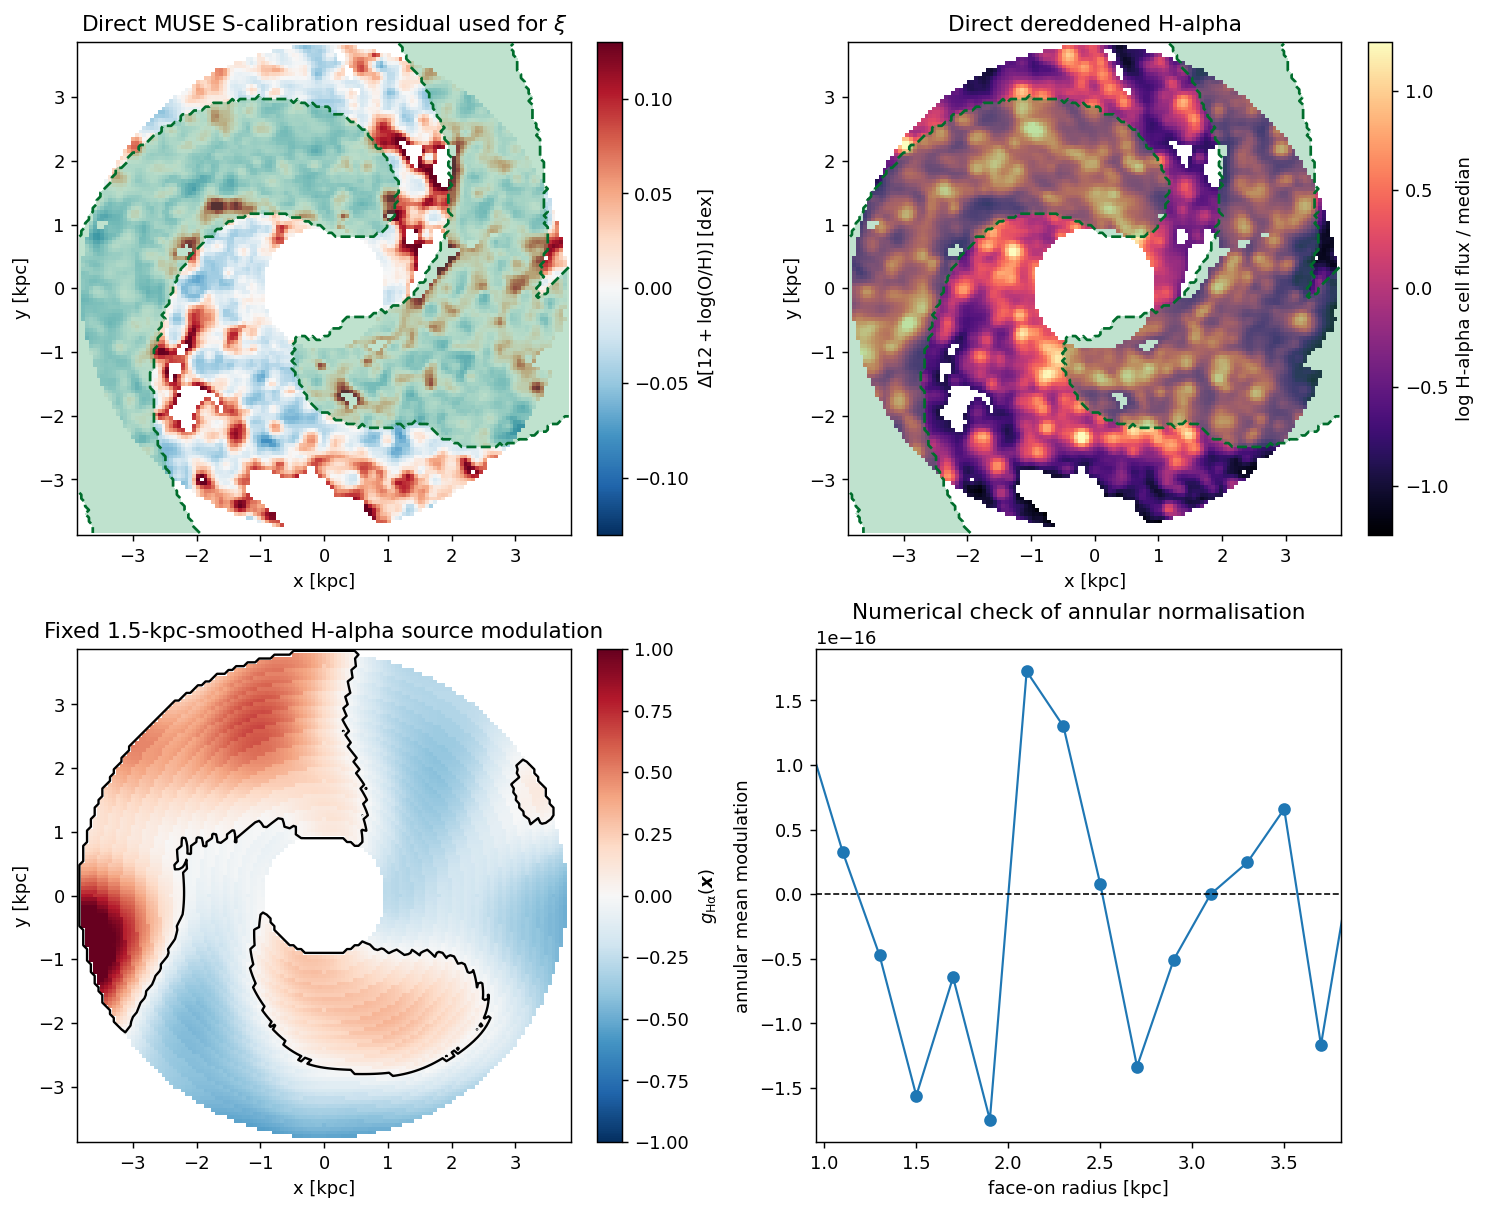

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11.2, 9.2), constrained_layout=True)

residual_image = axes[0, 0].pcolormesh(
    pixel_X, pixel_Y,
    np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
    shading="nearest", cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-0.13, vcenter=0.0, vmax=0.13),
)
axes[0, 0].set_title(r"Direct MUSE S-calibration residual used for $\xi$")
fig.colorbar(
    residual_image, ax=axes[0, 0],
    label=r"$\Delta[12+\log({\rm O/H})]$ [dex]",
)

halpha_plot = np.full(pixel_X.shape, np.nan)
halpha_plot[source_valid_grid] = (
    np.log10(source_halpha_flux) - np.median(np.log10(source_halpha_flux))
)
halpha_image = axes[0, 1].pcolormesh(
    pixel_X, pixel_Y, halpha_plot, shading="nearest", cmap="magma",
    vmin=-1.25, vmax=1.25,
)
axes[0, 1].set_title("Direct dereddened H-alpha")
fig.colorbar(
    halpha_image, ax=axes[0, 1], label="log H-alpha cell flux / median",
)

arm_mask_grid = np.isin(environment_label_grid, [5, 6])
for axis in axes[0]:
    axis.contourf(
        pixel_X, pixel_Y, arm_mask_grid.astype(float), levels=[0.5, 1.5],
        colors=["#2ca25f"], alpha=0.30, zorder=4,
    )
    axis.contour(
        pixel_X, pixel_Y, arm_mask_grid.astype(float), levels=[0.5],
        colors="#006d2c", linestyles="--", linewidths=1.5, zorder=5,
    )

template_image = axes[1, 0].pcolormesh(
    pixel_X, pixel_Y, np.where(geometry_mask, source_modulation_grid, np.nan),
    shading="nearest", cmap="RdBu_r", norm=TwoSlopeNorm(
        vmin=min(-1.0, float(np.nanpercentile(source_modulation_grid[geometry_mask], 2))),
        vcenter=0.0,
        vmax=max(1.0, float(np.nanpercentile(source_modulation_grid[geometry_mask], 98))),
    ),
)
axes[1, 0].contour(
    pixel_X, pixel_Y, source_modulation_grid, levels=[0.0],
    colors="black", linewidths=1.3,
)
axes[1, 0].set_title("Fixed 1.5-kpc-smoothed H-alpha source modulation")
fig.colorbar(template_image, ax=axes[1, 0], label=r"$g_{\rm H\alpha}(\boldsymbol{x})$")

radial_centres = 0.5 * (
    template_radial_edges[:-1] + template_radial_edges[1:]
)
radial_template_mean = np.asarray([
    np.mean(source_modulation_grid[
        geometry_mask & (template_radial_bin == bin_index)
    ]) if np.any(geometry_mask & (template_radial_bin == bin_index)) else np.nan
    for bin_index in range(len(radial_centres))
])
axes[1, 1].plot(radial_centres, radial_template_mean, "o-", lw=1.2)
axes[1, 1].axhline(0.0, color="black", ls="--", lw=0.9)
axes[1, 1].set_xlim(R_MIN_KPC, R_MAX_KPC)
axes[1, 1].set_xlabel("face-on radius [kpc]")
axes[1, 1].set_ylabel("annular mean modulation")
axes[1, 1].set_title("Numerical check of annular normalisation")

for axis in axes.ravel():
    if axis is not axes[1, 1]:
        axis.set_aspect("equal")
        axis.set_xlabel("x [kpc]")
        axis.set_ylabel("y [kpc]")

fig.savefig(OUTPUT_DIR / "ngc4254_phangs_morphology.png", bbox_inches="tight")
display_figure(fig)


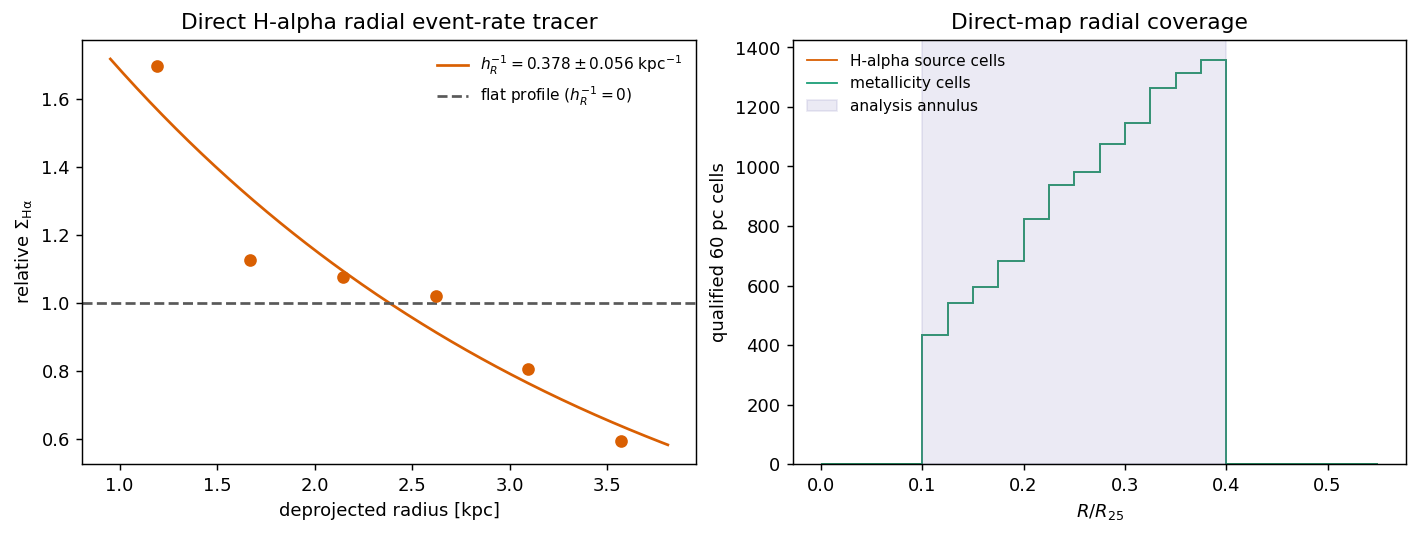

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.0), constrained_layout=True)
rate_radius_kpc = rate_centres_r25 * R25_KPC
normalised_rate = rate_surface_density / np.exp(
    np.mean(np.log(rate_surface_density[positive_rate_bins]))
)
axes[0].scatter(rate_radius_kpc[positive_rate_bins],
                normalised_rate[positive_rate_bins], color="#d95f02", zorder=3)
radial_plot = np.linspace(R_MIN_KPC, R_MAX_KPC, 300)
axes[0].plot(
    radial_plot,
    np.exp(rate_log_slope_halpha * (radial_plot - np.mean(rate_radius_kpc))),
    color="#d95f02",
    label=fr"$h_R^{{-1}}={-rate_log_slope_halpha:.3f}\pm{rate_log_slope_halpha_error:.3f}$ kpc$^{{-1}}$",
)
axes[0].axhline(1.0, color="0.35", ls="--", label=r"flat profile ($h_R^{-1}=0$)")
axes[0].set_xlabel("deprojected radius [kpc]")
axes[0].set_ylabel(r"relative $\Sigma_{\rm H\alpha}$")
axes[0].set_title("Direct H-alpha radial event-rate tracer")
axes[0].legend(frameon=False, fontsize=8.5)

coverage_edges = np.arange(0.0, 0.551, 0.025)
metallicity_counts, _ = np.histogram(r_r25, coverage_edges)
source_counts, _ = np.histogram(source_r_kpc / R25_KPC, coverage_edges)
axes[1].stairs(source_counts, coverage_edges, color="#d95f02",
               label="H-alpha source cells")
axes[1].stairs(metallicity_counts, coverage_edges, color="#1b9e77",
               label="metallicity cells")
axes[1].axvspan(R_MIN_R25, R_MAX_R25, color="#7570b3", alpha=0.14,
                label="analysis annulus")
axes[1].set_xlabel(r"$R/R_{25}$")
axes[1].set_ylabel("qualified 60 pc cells")
axes[1].set_title("Direct-map radial coverage")
axes[1].legend(frameon=False, fontsize=8.5)

fig.savefig(OUTPUT_DIR / "ngc4254_phangs_radial_selection.png",
            bbox_inches="tight")
display_figure(fig)


## 4. Exact finite-window statistic and observational transfer

The metallicity field entering the statistic is the direct $S$-calibration
map above after independent 0.2 kpc annular means have been removed.  The
zero-padded FFT computes the numerator, symmetric endpoint second moment, and
valid pair count for every grid lag.  Because both lag orientations are
included, the final counts are divided by two to report unordered pairs.

Uncertainty combines a 48-block spatial jackknife with line-flux Monte Carlo.
The Monte Carlo also estimates, bin by bin, how much correlated measurement
noise contributes to the numerator and endpoint second moment.  This fixed
transfer is applied to both KT18 and complete KTZ without adding another free
parameter.  The analytic Li21 Gaussian beam correction is applied separately
to the theoretical injection width.


In [7]:
separation_edges = np.arange(
    0.5 * PIXEL_SIZE_KPC,
    5.0 + 0.5 * PIXEL_SIZE_KPC + 1.0e-9,
    PIXEL_SIZE_KPC,
)
separation_centres = 0.5 * (separation_edges[:-1] + separation_edges[1:])
n_bins = len(separation_centres)

lag_y = np.arange(-(pixel_X.shape[0] - 1), pixel_X.shape[0]) * PIXEL_SIZE_KPC
lag_x = np.arange(-(pixel_X.shape[1] - 1), pixel_X.shape[1]) * PIXEL_SIZE_KPC
lag_X, lag_Y = np.meshgrid(lag_x, lag_y)
lag_R = np.hypot(lag_X, lag_Y)
lag_bin = np.digitize(lag_R.ravel(), separation_edges) - 1
valid_lag_bin = (lag_bin >= 0) & (lag_bin < n_bins) & (lag_R.ravel() > 0)


def fft_pair_sums(values: np.ndarray, valid: np.ndarray):
    """Exact ordered-pair sums on a finite, non-periodic masked grid."""
    mask = valid.astype(float)
    field = np.where(valid, values, 0.0)
    power = field**2
    pair_grid = fftconvolve(mask, mask[::-1, ::-1], mode="full")
    numerator_grid = fftconvolve(field, field[::-1, ::-1], mode="full")
    endpoint_grid = 0.5 * (
        fftconvolve(power, mask[::-1, ::-1], mode="full")
        + fftconvolve(mask, power[::-1, ::-1], mode="full")
    )
    bins = lag_bin[valid_lag_bin]
    counts = np.bincount(
        bins, weights=pair_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    numerator = np.bincount(
        bins, weights=numerator_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    endpoint = np.bincount(
        bins, weights=endpoint_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    return numerator, endpoint, counts


def fft_pair_product_statistic(
    region_mask: np.ndarray | None = None,
    centre_residual: bool = True,
    metallicity_values: np.ndarray | None = None,
    valid_mask: np.ndarray | None = None,
):
    """Li21 detrending plus the validation-matched exhaustive estimator."""
    if region_mask is None:
        region_mask = np.ones(pixel_X.shape, dtype=bool)
    if metallicity_values is None:
        metallicity_values = metallicity_grid
    if valid_mask is None:
        valid_mask = pixel_valid_grid
    valid = valid_mask & region_mask & np.isfinite(metallicity_values)
    residual_grid, _ = annular_residual_map(metallicity_values, valid)
    valid &= np.isfinite(residual_grid)
    residual_mean = float(np.mean(residual_grid[valid]))
    if centre_residual:
        residual_grid = residual_grid - residual_mean
    numerator, endpoint, ordered_counts = fft_pair_sums(residual_grid, valid)
    xi = np.divide(
        numerator, endpoint, out=np.full(n_bins, np.nan), where=endpoint > 0
    )
    unordered_counts = np.rint(0.5 * ordered_counts).astype(np.int64)
    numerator_mean = np.divide(
        numerator, ordered_counts, out=np.full(n_bins, np.nan),
        where=ordered_counts > 0,
    )
    endpoint_mean = np.divide(
        endpoint, ordered_counts, out=np.full(n_bins, np.nan),
        where=ordered_counts > 0,
    )
    return (xi, unordered_counts, residual_mean, numerator_mean,
            endpoint_mean, residual_grid)


(xi_observed, pair_counts, residual_mean, observed_numerator_mean,
 observed_endpoint_mean, observed_residual_grid) = fft_pair_product_statistic()
xi_uncentred = fft_pair_product_statistic(centre_residual=False)[0]


def delete_one_block_jackknife(block_label_grid: np.ndarray):
    labels = np.unique(block_label_grid[pixel_valid_grid])
    curves = []
    means = []
    for label in labels:
        retained = block_label_grid != label
        curve, _, mean_value, _, _, _ = fft_pair_product_statistic(retained)
        curves.append(curve)
        means.append(mean_value)
    curves = np.asarray(curves)
    means = np.asarray(means)
    factor = (len(labels) - 1.0) / len(labels)
    difference = np.nan_to_num(curves - np.nanmean(curves, axis=0), nan=0.0)
    covariance = factor * difference.T @ difference
    mean_error = float(np.sqrt(factor * np.sum((means - np.mean(means))**2)))
    return curves, covariance, mean_error


azimuth_12_grid = np.floor(pixel_PHI / (2.0 * np.pi) * 12).astype(int)
radial_block_edges = np.sqrt(np.linspace(R_MIN_KPC**2, R_MAX_KPC**2, 5))
radial_block_grid = np.clip(
    np.digitize(pixel_R, radial_block_edges) - 1, 0, 3
)
spatial_48_grid = 12 * radial_block_grid + azimuth_12_grid

sector_curves, sector_covariance, sector_mean_error = (
    delete_one_block_jackknife(azimuth_12_grid)
)
jackknife_curves, jackknife_covariance, residual_mean_error = (
    delete_one_block_jackknife(spatial_48_grid)
)
n_jackknife = len(np.unique(spatial_48_grid[pixel_valid_grid]))

# Re-evaluate the nonlinear abundance, selection, and detrending pipeline for
# every line-flux Monte Carlo realisation.  The fixed-mask curves are retained
# as a paired control; the likelihood covariance uses the dynamic-selection
# curves, so threshold crossings are propagated rather than conditioned away.
fixed_selection_measurement_curves = np.empty((N_FLUX_MC, n_bins))
dynamic_selection_measurement_curves = np.empty((N_FLUX_MC, n_bins))
noise_numerator_means = np.empty((N_FLUX_MC, n_bins))
noise_endpoint_means = np.empty((N_FLUX_MC, n_bins))
selection_pixel_counts = np.empty(N_FLUX_MC, dtype=int)
for draw_index in range(N_FLUX_MC):
    draw_map = np.asarray(metallicity_mc_grid[draw_index], dtype=float)
    fixed_draw_map = np.where(np.isfinite(draw_map), draw_map, metallicity_grid)
    fixed_selection_measurement_curves[draw_index] = (
        fft_pair_product_statistic(metallicity_values=fixed_draw_map)[0]
    )

    draw_valid = selection_mc_grid[draw_index] & np.isfinite(draw_map)
    selection_pixel_counts[draw_index] = int(np.sum(draw_valid))
    dynamic_selection_measurement_curves[draw_index] = (
        fft_pair_product_statistic(
            metallicity_values=draw_map, valid_mask=draw_valid
        )[0]
    )
    noise_map = draw_map - metallicity_grid
    noise_residual, _ = annular_residual_map(noise_map, draw_valid)
    noise_valid = draw_valid & np.isfinite(noise_residual)
    noise_numerator, noise_endpoint, noise_counts = fft_pair_sums(
        noise_residual, noise_valid
    )
    noise_numerator_means[draw_index] = np.divide(
        noise_numerator, noise_counts, out=np.zeros(n_bins),
        where=noise_counts > 0,
    )
    noise_endpoint_means[draw_index] = np.divide(
        noise_endpoint, noise_counts, out=np.zeros(n_bins),
        where=noise_counts > 0,
    )

measurement_curves = dynamic_selection_measurement_curves
selection_curve_difference = (
    dynamic_selection_measurement_curves
    - fixed_selection_measurement_curves
)
selection_response_bias = np.nanmean(selection_curve_difference, axis=0)
selection_bias_covariance = np.outer(
    selection_response_bias, selection_response_bias
)
measurement_covariance = np.cov(measurement_curves, rowvar=False, ddof=1)
noise_numerator_mean = np.nanmean(noise_numerator_means, axis=0)
noise_endpoint_mean = np.nanmean(noise_endpoint_means, axis=0)
signal_endpoint_mean = np.clip(
    observed_endpoint_mean - noise_endpoint_mean, 0.0, None
)
observation_signal_fraction = np.divide(
    signal_endpoint_mean, observed_endpoint_mean,
    out=np.ones(n_bins), where=observed_endpoint_mean > 0,
)
observation_signal_fraction = np.clip(observation_signal_fraction, 0.05, 1.0)
observation_noise_bias = np.divide(
    noise_numerator_mean, observed_endpoint_mean,
    out=np.zeros(n_bins), where=observed_endpoint_mean > 0,
)


from scripts.phangs_annular_transfer import (
    apply_annular_detrending_transfer,
    load_or_build_annular_detrending_transfer,
    projected_numerator_and_denominator,
)

annular_transfer_path = (
    OUTPUT_DIR / "ngc4254_annular_detrending_transfer.npz"
)
annular_detrending_transfer = load_or_build_annular_detrending_transfer(
    annular_transfer_path, pixel_valid_grid, pixel_R, PIXEL_SIZE_KPC,
    separation_edges, separation_centres, ANNULUS_WIDTH_KPC,
)


def apply_observation_transfer(intrinsic_xi: np.ndarray) -> np.ndarray:
    """Apply annular detrending, then fixed correlated-noise transfer."""
    detrended_xi = apply_annular_detrending_transfer(
        intrinsic_xi, annular_detrending_transfer, zero_lag=1.0,
    )
    return (observation_signal_fraction * detrended_xi
            + observation_noise_bias)


def apply_observation_transfer_components(
    intrinsic_components: dict[str, np.ndarray],
) -> dict[str, np.ndarray]:
    """Project KTZ components with one common post-detrending variance."""
    intrinsic_total = sum(intrinsic_components.values())
    _, projected_denominator = projected_numerator_and_denominator(
        intrinsic_total, annular_detrending_transfer, zero_lag=1.0,
    )
    first_bin_total = float(intrinsic_total[0])
    if not np.isfinite(first_bin_total) or abs(first_bin_total) < 1.0e-12:
        zero_lag_shares = {name: 0.25 for name in intrinsic_components}
    else:
        zero_lag_shares = {
            name: float(values[0] / first_bin_total)
            for name, values in intrinsic_components.items()
        }
    share_sum = sum(zero_lag_shares.values())
    zero_lag_shares = {
        name: value / share_sum for name, value in zero_lag_shares.items()
    }
    projected = {}
    for name, values in intrinsic_components.items():
        projected_numerator, _ = projected_numerator_and_denominator(
            values, annular_detrending_transfer,
            zero_lag=zero_lag_shares[name],
        )
        projected[name] = observation_signal_fraction * np.divide(
            projected_numerator, projected_denominator,
            out=np.full_like(projected_numerator, np.nan),
            where=projected_denominator > 0.0,
        )
    return projected


# The paired dynamic-minus-fixed mean is not subtracted from the data: the
# observed map has one realised selection.  Its magnitude is instead carried
# as a conservative, fully correlated one-sigma selection systematic.
total_covariance_raw = (
    jackknife_covariance + measurement_covariance
    + selection_bias_covariance
)
xi_jackknife_error = np.sqrt(
    np.clip(np.diag(total_covariance_raw), 0.0, None)
)
xi_sector_error = np.sqrt(np.clip(np.diag(sector_covariance), 0.0, None))
xi_measurement_error = np.sqrt(
    np.clip(np.diag(measurement_covariance), 0.0, None)
)

fit_mask = (
    (separation_centres <= 5.0)
    & (pair_counts > 0)
    & np.isfinite(xi_observed)
    & np.all(np.isfinite(jackknife_curves), axis=0)
    & np.all(np.isfinite(measurement_curves), axis=0)
)
fit_indices = np.where(fit_mask)[0]
fit_covariance_raw = total_covariance_raw[np.ix_(fit_indices, fit_indices)]
covariance_shrinkage = 0.35
systematic_floor = 0.010
fit_covariance = (
    (1.0 - covariance_shrinkage) * fit_covariance_raw
    + covariance_shrinkage * np.diag(np.diag(fit_covariance_raw))
    + systematic_floor**2 * np.eye(len(fit_indices))
)
fit_cholesky = np.linalg.cholesky(fit_covariance)
np.savez_compressed(  # consumed by the exact-window joint stage (scripts/ktz_exact_window.py)
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_fit_covariance.npz",
    covariance=fit_covariance, raw_covariance=fit_covariance_raw,
    fit_indices=fit_indices, covariance_shrinkage=covariance_shrinkage,
    systematic_floor=systematic_floor,
)
covariance_reference_operator = np.linalg.solve(
    fit_covariance, fit_covariance_raw
)
regularised_chi2_reference_mean = float(
    np.trace(covariance_reference_operator)
)
regularised_chi2_reference_second_trace = float(
    np.trace(covariance_reference_operator @ covariance_reference_operator)
)
regularised_chi2_reference_effective_dof = float(
    regularised_chi2_reference_mean**2
    / regularised_chi2_reference_second_trace
)
fit_covariance_effective_rank = float(
    np.trace(fit_covariance)**2 / np.trace(fit_covariance @ fit_covariance)
)
print(
    'Covariance diagnostics: raw rank='
    f'{np.linalg.matrix_rank(fit_covariance_raw)}/{len(fit_indices)}, '
    f'fit-covariance participation rank={fit_covariance_effective_rank:.1f}, '
    f'regularised chi2 reference mean={regularised_chi2_reference_mean:.1f}, '
    f'Satterthwaite dof={regularised_chi2_reference_effective_dof:.1f}'
)

covariance_diagnostics = Table({
    "r_kpc": separation_centres,
    "pair_count": pair_counts,
    "xi_centered": xi_observed,
    "xi_uncentered": xi_uncentred,
    "centered_minus_uncentered": xi_observed - xi_uncentred,
    "total_error": xi_jackknife_error,
    "spatial_48_jackknife_error": np.sqrt(
        np.clip(np.diag(jackknife_covariance), 0.0, None)
    ),
    "line_flux_mc_error": xi_measurement_error,
    "azimuth_12_jackknife_error": xi_sector_error,
    "noise_signal_fraction": observation_signal_fraction,
    "noise_additive_bias": observation_noise_bias,
})
covariance_diagnostics.write(
    OUTPUT_DIR / "ngc4254_residual_covariance_diagnostics.csv",
    format="ascii.csv", overwrite=True,
)

annulus_sensitivity_rows = []
for annulus_name, lower_r25, upper_r25 in (
    ("R10_35", 0.10, 0.35),
    ("R10_40_primary", 0.10, 0.40),
    ("R15_35", 0.15, 0.35),
    ("R15_40", 0.15, 0.40),
):
    annulus_mask = (
        (pixel_R / R25_KPC >= lower_r25)
        & (pixel_R / R25_KPC <= upper_r25)
    )
    annulus_curve, annulus_counts, annulus_mean, _, _, _ = (
        fft_pair_product_statistic(annulus_mask)
    )
    annulus_sensitivity_rows.extend([
        (annulus_name, lower_r25, upper_r25,
         int(np.sum(pixel_valid_grid & annulus_mask)), annulus_mean,
         separation_centres[index], annulus_counts[index], annulus_curve[index])
        for index in range(n_bins)
    ])
Table(
    rows=annulus_sensitivity_rows,
    names=("annulus", "rmin_r25", "rmax_r25", "n_pixels", "residual_mean",
           "r_kpc", "pair_count", "xi_centered"),
).write(OUTPUT_DIR / "ngc4254_annulus_sensitivity.csv",
        format="ascii.csv", overwrite=True)


Covariance diagnostics: raw rank=83/83, fit-covariance participation rank=13.4, regularised chi2 reference mean=16.7, Satterthwaite dof=15.1


## 4.1 Data-dependent selection response

The geometric coverage window is fixed, but the line-$S/N$, BPT, and
$W_{\rm H\alpha}$ decisions are functions of noisy measurements.  The flux
Monte Carlo therefore recomputes those three decisions in every realisation.
The dynamic-selection curves enter the measurement covariance; fixed-mask
curves are retained only as a paired diagnostic.  We do not subtract the
paired mean shift from the observed curve, because a plug-in bootstrap centred
on the noisy observed flux does not identify an unbiased correction.  Instead,
its outer product is included as a conservative correlated systematic.

Two robustness checks distinguish ordinary holes from endogenous selection.
First, the nominal curve is recomputed over a grid of line-$S/N$ and
$W_{\rm H\alpha}$ thresholds.  Second, line-ratio vectors are permuted within
0.2-kpc annuli while the observed H$\alpha$ brightness, errors, coverage, PSF
noise correlation, and complete selection logic are retained.  This destroys
intrinsic spatial abundance correlation while preserving radial one-point
line-ratio distributions and their coupling to detectability.  A recovered
non-zero curve is therefore a selection/null diagnostic, not a physical KTZ
prediction.  It is deliberately more limited than a native-cube injection:
the released, PSF-matched line maps are the starting point.


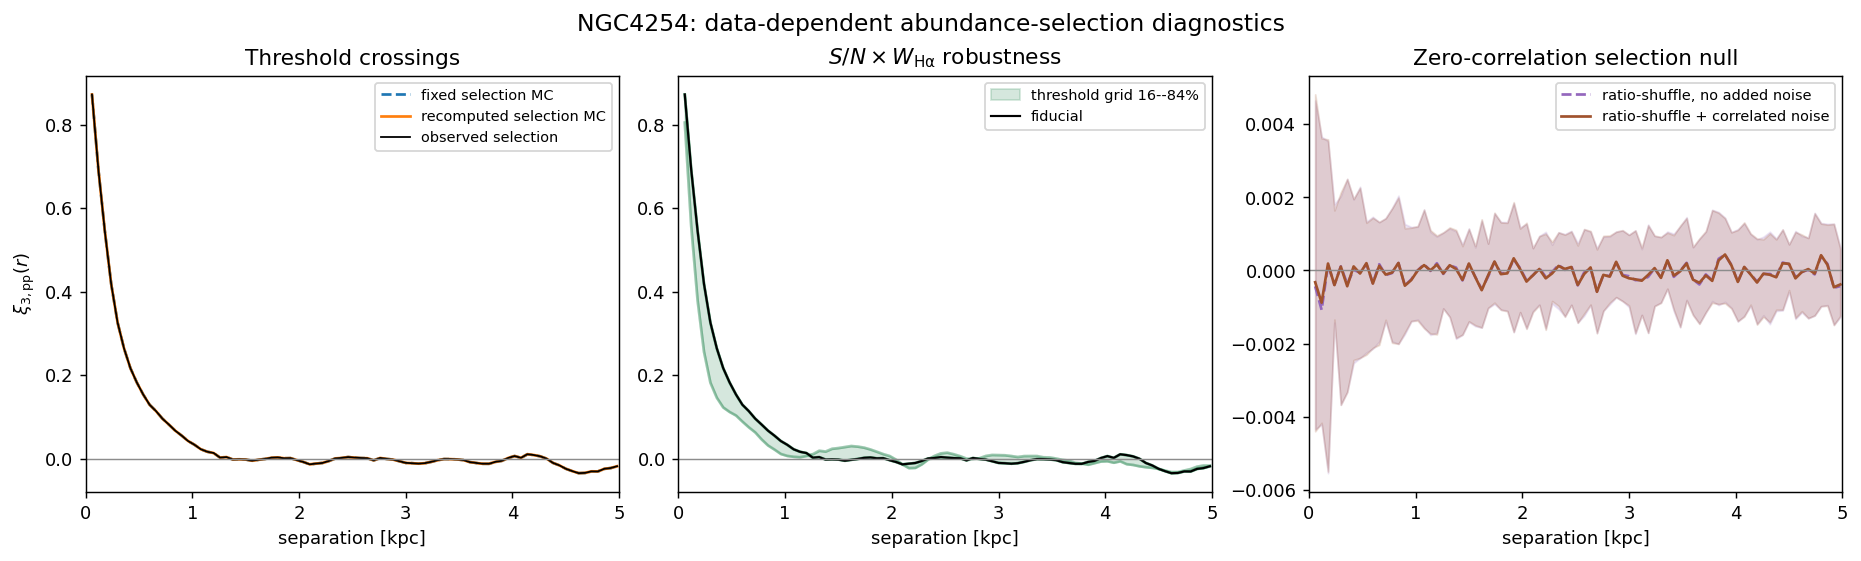

selection diagnostic,value
str41,str32
nominal valid pixels,11152
"dynamic valid pixels [p16, p50, p84]","[11151.0, 11152.0, 11152.16]"
paired selection shift [Mahalanobis],0.016307314892807952
paired max |delta xi|,0.00021252755807691065
threshold-grid max |delta xi|,0.16699889100749632
noisy zero-correlation null [Mahalanobis],0.07771198904139502
noisy null max |median xi|,0.0008797121661464979


In [8]:
selection_sn_grid = np.asarray([2.0, 3.0, 5.0])
selection_ew_grid = np.asarray([3.0, 6.0, 12.0])
threshold_curves = []
threshold_rows = []
for sn_cut in selection_sn_grid:
    for ew_cut in selection_ew_grid:
        threshold_valid = li21_selection_mask(
            line_flux, metallicity_grid, corrected_line_flux,
            line_sn_min=float(sn_cut), halpha_ew_min=float(ew_cut),
        ) & np.isfinite(metallicity_error_grid)
        threshold_curve, threshold_pairs, _, _, _, _ = (
            fft_pair_product_statistic(valid_mask=threshold_valid)
        )
        threshold_curves.append(threshold_curve)
        threshold_rows.append((
            float(sn_cut), float(ew_cut), int(np.sum(threshold_valid)),
            int(np.sum(threshold_pairs)),
            float(np.nanmax(np.abs(threshold_curve - xi_observed))),
        ))
threshold_curves = np.asarray(threshold_curves)


def annular_line_ratio_shuffle(
    rng: np.random.Generator,
) -> dict[str, np.ndarray]:
    """Destroy spatial ratio correlation while preserving annular marginals."""
    ratio_pool = geometry_mask & np.isfinite(r_band_flux)
    for name in LINE_EXTENSIONS:
        ratio_pool &= (
            np.isfinite(line_flux[name]) & (line_flux[name] > 0)
            & np.isfinite(line_error[name]) & (line_error[name] > 0)
            & (line_coverage[name] >= LINE_COVERAGE_MIN)
        )
    ratio_pool &= np.isfinite(line_flux["ha"]) & (line_flux["ha"] > 0)

    shuffled = {
        name: np.full(pixel_X.shape, np.nan, dtype=float)
        for name in LINE_EXTENSIONS
    }
    shuffled["ha"][ratio_pool] = line_flux["ha"][ratio_pool]
    radial_edges = np.arange(
        0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC, ANNULUS_WIDTH_KPC
    )
    radial_bin = np.digitize(pixel_R, radial_edges) - 1
    for bin_index in range(len(radial_edges) - 1):
        receiver = np.flatnonzero(ratio_pool & (radial_bin == bin_index))
        if len(receiver) < MIN_PIXELS_PER_ANNULUS:
            continue
        donor = rng.permutation(receiver)
        receiver_ha = line_flux["ha"].ravel()[receiver]
        donor_ha = line_flux["ha"].ravel()[donor]
        for name in LINE_EXTENSIONS:
            if name == "ha":
                continue
            donor_ratio = line_flux[name].ravel()[donor] / donor_ha
            shuffled[name].ravel()[receiver] = receiver_ha * donor_ratio
    return shuffled


N_SELECTION_NULL = 40
selection_null_rng = np.random.default_rng(
    91000 + int(''.join(character for character in GALAXY_NAME if character.isdigit()))
)
selection_null_noiseless = np.empty((N_SELECTION_NULL, n_bins))
selection_null_with_noise = np.empty((N_SELECTION_NULL, n_bins))
for null_index in range(N_SELECTION_NULL):
    null_flux = annular_line_ratio_shuffle(selection_null_rng)
    null_metallicity, _, null_corrected = scal_metallicity(null_flux)
    null_valid = li21_selection_mask(
        null_flux, null_metallicity, null_corrected
    )
    selection_null_noiseless[null_index] = fft_pair_product_statistic(
        metallicity_values=null_metallicity, valid_mask=null_valid
    )[0]

    noisy_null_flux = {
        name: null_flux[name] + line_error[name] * correlated_unit_noise(
            pixel_X.shape, noise_sigma_grid_pixel, selection_null_rng
        )
        for name in LINE_EXTENSIONS
    }
    noisy_null_metallicity, _, noisy_null_corrected = scal_metallicity(
        noisy_null_flux
    )
    noisy_null_valid = li21_selection_mask(
        noisy_null_flux, noisy_null_metallicity, noisy_null_corrected
    )
    selection_null_with_noise[null_index] = fft_pair_product_statistic(
        metallicity_values=noisy_null_metallicity,
        valid_mask=noisy_null_valid,
    )[0]


fixed_p16, fixed_p50, fixed_p84 = np.nanpercentile(
    fixed_selection_measurement_curves, [16.0, 50.0, 84.0], axis=0
)
dynamic_p16, dynamic_p50, dynamic_p84 = np.nanpercentile(
    dynamic_selection_measurement_curves, [16.0, 50.0, 84.0], axis=0
)
threshold_p16, threshold_p84 = np.nanpercentile(
    threshold_curves, [16.0, 84.0], axis=0
)
null_noiseless_p16, null_noiseless_p50, null_noiseless_p84 = np.nanpercentile(
    selection_null_noiseless, [16.0, 50.0, 84.0], axis=0
)
null_noisy_p16, null_noisy_p50, null_noisy_p84 = np.nanpercentile(
    selection_null_with_noise, [16.0, 50.0, 84.0], axis=0
)

selection_bias_fit = selection_response_bias[fit_indices]
selection_bias_mahalanobis = float(np.sqrt(
    selection_bias_fit @ np.linalg.solve(fit_covariance, selection_bias_fit)
))
selection_null_mean_fit = np.nanmean(
    selection_null_with_noise[:, fit_indices], axis=0
)
selection_null_mahalanobis = float(np.sqrt(
    selection_null_mean_fit
    @ np.linalg.solve(fit_covariance, selection_null_mean_fit)
))

selection_response_table = Table({
    "r_kpc": separation_centres,
    "xi_observed": xi_observed,
    "fixed_mc_p16": fixed_p16,
    "fixed_mc_p50": fixed_p50,
    "fixed_mc_p84": fixed_p84,
    "dynamic_mc_p16": dynamic_p16,
    "dynamic_mc_p50": dynamic_p50,
    "dynamic_mc_p84": dynamic_p84,
    "dynamic_minus_fixed_mean": selection_response_bias,
    "threshold_p16": threshold_p16,
    "threshold_p84": threshold_p84,
    "null_noiseless_p16": null_noiseless_p16,
    "null_noiseless_p50": null_noiseless_p50,
    "null_noiseless_p84": null_noiseless_p84,
    "null_noisy_p16": null_noisy_p16,
    "null_noisy_p50": null_noisy_p50,
    "null_noisy_p84": null_noisy_p84,
})
selection_response_table.write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_response.csv",
    format="ascii.csv", overwrite=True,
)
Table(
    rows=threshold_rows,
    names=("line_sn_min", "halpha_ew_min_angstrom", "n_pixels",
           "total_pairs", "max_abs_delta_xi"),
).write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_threshold_grid.csv",
    format="ascii.csv", overwrite=True,
)

selection_summary = {
    "galaxy": GALAXY_NAME,
    "nominal_valid_pixels": int(np.sum(pixel_valid_grid)),
    "dynamic_valid_pixels_p16_p50_p84": [
        float(value) for value in np.percentile(
            selection_pixel_counts, [16.0, 50.0, 84.0]
        )
    ],
    "paired_selection_bias_mahalanobis": selection_bias_mahalanobis,
    "paired_selection_max_abs_delta_xi": float(
        np.nanmax(np.abs(selection_response_bias[fit_indices]))
    ),
    "threshold_grid_max_abs_delta_xi": float(np.nanmax(
        np.abs(threshold_curves[:, fit_indices] - xi_observed[fit_indices])
    )),
    "annular_shuffle_noisy_null_mahalanobis": selection_null_mahalanobis,
    "annular_shuffle_noisy_null_max_abs_median_xi": float(
        np.nanmax(np.abs(null_noisy_p50[fit_indices]))
    ),
    "null_realisations": N_SELECTION_NULL,
    "interpretation": (
        "diagnostic conditional on released PSF-matched line maps; "
        "not a native-cube selection correction"
    ),
}
(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_summary.json").write_text(
    json.dumps(selection_summary, indent=2), encoding="utf-8"
)

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.2), constrained_layout=True)
axes[0].fill_between(
    separation_centres, fixed_p16, fixed_p84, color="tab:blue", alpha=0.16
)
axes[0].plot(
    separation_centres, fixed_p50, color="tab:blue", ls="--",
    label="fixed selection MC"
)
axes[0].fill_between(
    separation_centres, dynamic_p16, dynamic_p84,
    color="tab:orange", alpha=0.22,
)
axes[0].plot(
    separation_centres, dynamic_p50, color="tab:orange",
    label="recomputed selection MC",
)
axes[0].plot(
    separation_centres, xi_observed, color="black", lw=1.0,
    label="observed selection",
)
axes[0].set_title("Threshold crossings")
axes[0].legend(fontsize=8)

for curve in threshold_curves:
    axes[1].plot(separation_centres, curve, color="seagreen", alpha=0.18)
axes[1].fill_between(
    separation_centres, threshold_p16, threshold_p84,
    color="seagreen", alpha=0.20, label="threshold grid 16--84%",
)
axes[1].plot(separation_centres, xi_observed, color="black", lw=1.2,
             label="fiducial")
axes[1].set_title(r"$S/N\times W_{\rm H\alpha}$ robustness")
axes[1].legend(fontsize=8)

axes[2].fill_between(
    separation_centres, null_noiseless_p16, null_noiseless_p84,
    color="tab:purple", alpha=0.16,
)
axes[2].plot(
    separation_centres, null_noiseless_p50, color="tab:purple", ls="--",
    label="ratio-shuffle, no added noise",
)
axes[2].fill_between(
    separation_centres, null_noisy_p16, null_noisy_p84,
    color="sienna", alpha=0.18,
)
axes[2].plot(
    separation_centres, null_noisy_p50, color="sienna",
    label="ratio-shuffle + correlated noise",
)
axes[2].set_title("Zero-correlation selection null")
axes[2].legend(fontsize=8)

for axis in axes:
    axis.axhline(0.0, color="0.55", lw=0.8)
    axis.set_xlim(0.0, 5.0)
    axis.set_xlabel("separation [kpc]")
axes[0].set_ylabel(r"$\xi_{3,{\rm pp}}(r)$")
fig.suptitle(
    f"{GALAXY_NAME}: data-dependent abundance-selection diagnostics",
    fontsize=13,
)
selection_figure_path = (
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_response_diagnostic.png"
)
fig.savefig(selection_figure_path, bbox_inches="tight")
display_figure(fig)

display(Table(
    rows=[
        ("nominal valid pixels", int(np.sum(pixel_valid_grid))),
        ("dynamic valid pixels [p16, p50, p84]",
         str(selection_summary["dynamic_valid_pixels_p16_p50_p84"])),
        ("paired selection shift [Mahalanobis]",
         selection_bias_mahalanobis),
        ("paired max |delta xi|", selection_summary[
            "paired_selection_max_abs_delta_xi"]),
        ("threshold-grid max |delta xi|", selection_summary[
            "threshold_grid_max_abs_delta_xi"]),
        ("noisy zero-correlation null [Mahalanobis]",
         selection_null_mahalanobis),
        ("noisy null max |median xi|", selection_summary[
            "annular_shuffle_noisy_null_max_abs_median_xi"]),
    ],
    names=("selection diagnostic", "value"),
))


In [9]:
# Compress every unordered pair into deterministic separation/radius cells.
# The arbitrary mask is sampled exactly at both endpoints and on a half-pixel
# grid at every possible pair midpoint; no pair or arm-shape fit is sampled.
from scripts.phangs_pair_geometry import compress_regular_grid_template_pairs

n_pixels = len(r_kpc)
window_signature = hashlib.sha256(np.column_stack((
    x_kpc, y_kpc, metal_residual_centered
)).tobytes()).hexdigest()
pair_separation_subbins = 12
pair_midpoint_radial_edges = np.linspace(0.0, R_MAX_KPC, 257)

pair_geometry_signature = hashlib.sha256(json.dumps({
    "version": 2,
    "window": window_signature,
    "environment_mask": environment_mask_hash,
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "pixel_size_kpc": PIXEL_SIZE_KPC,
    "separation_edges": separation_edges.tolist(),
    "separation_subbins": pair_separation_subbins,
    "midpoint_radial_edges": pair_midpoint_radial_edges.tolist(),
}, sort_keys=True).encode()).hexdigest()
pair_geometry_path = (
    OUTPUT_DIR / "ngc4254_muse_scal_exhaustive_pair_geometry.npz"
)

pair_geometry_loaded = False
if pair_geometry_path.exists():
    with np.load(pair_geometry_path, allow_pickle=False) as cached:
        if str(cached["signature"].item()) == pair_geometry_signature:
            pair_geometry = {
                name: cached[name] for name in cached.files
                if name != "signature"
            }
            pair_geometry_loaded = True

if not pair_geometry_loaded:
    pair_geometry = compress_regular_grid_template_pairs(
        valid=pixel_valid_grid,
        x_grid=pixel_X,
        y_grid=pixel_Y,
        source_modulation_grid=source_modulation_grid,
        midpoint_modulation_grid=midpoint_source_modulation_grid,
        separation_edges=separation_edges,
        radial_edges=pair_midpoint_radial_edges,
        separation_subbins=pair_separation_subbins,
    )
    np.savez_compressed(
        pair_geometry_path,
        signature=np.asarray(pair_geometry_signature),
        **pair_geometry,
    )
else:
    print(f"Loaded matching exhaustive pair geometry: {pair_geometry_path.name}")

pair_counts_geometry = np.rint(np.bincount(
    pair_geometry["output_bin"],
    weights=pair_geometry["counts"],
    minlength=n_bins,
)).astype(np.int64)
if not np.array_equal(pair_counts_geometry, pair_counts):
    raise RuntimeError(
        "FFT and exhaustive compressed pair counts disagree; check bin edges."
    )
pair_count_total = int(np.sum(pair_geometry["counts"]))

print(f"Face-on analysis pixels: {n_pixels:,}")
print(f"All unordered pairs with r < 5 kpc: {pair_count_total:,}")
print(f"Occupied fine pair cells: {len(pair_geometry['counts']):,}")
print(f"MCMC fit bins (0 < r < 5 kpc): {len(fit_indices)}")
print(f"Residual mean: {residual_mean:+.6f} +/- {residual_mean_error:.6f} dex")
print(
    "Median measurement-noise signal fraction: "
    f"{np.nanmedian(observation_signal_fraction[fit_indices]):.3f}"
)


Face-on analysis pixels: 11,152
All unordered pairs with r < 5 kpc: 49,010,550
Occupied fine pair cells: 177,852
MCMC fit bins (0 < r < 5 kpc): 83
Residual mean: -0.000000 +/- 0.000001 dex
Median measurement-noise signal fraction: 1.000


### 5.1 Full-pair KTZ emulator for the direct two-dimensional H-alpha template

The connected term samples the fixed smoothed H-alpha modulation at every pair midpoint, while the mean-field term uses its values at both endpoints. The template retains non-logarithmic branches and asymmetry. Its 1.5-kpc low-pass FWHM is not the 120-pc observing beam or a fitted diffusion scale. Mask-aware smoothing limits, but does not guarantee the removal of, compact structure that could overlap with $C_{\rm NP}$. The 0.5/1.0/1.5-kpc comparison tests this allocation of power.


In [10]:
from scripts.phangs_template_ktz import (
    COMPONENT_ORDER,
    correlation_components_from_template_basis,
    correlation_from_template_basis,
    template_cnp_pair_basis_exact,
    template_pair_basis,
)


def ktz_pair_basis(
    ell_value: float, epsilon_value: float,
    rate_log_slope_values: float | np.ndarray, quadrature_nodes: int = 20,
) -> dict[str, np.ndarray]:
    del quadrature_nodes
    return template_pair_basis(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_value, epsilon_value, rate_log_slope_values,
    )


def ktz_cnp_pair_basis_exact(
    ell_value: float, epsilon_value: float, rate_log_slope_value: float,
    source_length: float, quadrature_nodes: int = 20,
) -> dict[str, np.ndarray]:
    return template_cnp_pair_basis_exact(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_value, epsilon_value, rate_log_slope_value, source_length,
        quadrature_nodes=quadrature_nodes,
    )


component_order = COMPONENT_ORDER
component_colors = {
    "CP0": "#7fc97f", "CPN": "#ffff99",
    "CM": "#fdc086", "CNP": "#beaed4",
}
component_labels = {
    "CP0": r"$C_{{\rm 2p},0}$", "CPN": r"$C_{{\rm 2p},N}$",
    "CM": r"$C_{\rm M}$", "CNP": r"$C_{\rm NP}$",
}


def correlation_components_from_basis(*args, **kwargs):
    return correlation_components_from_template_basis(*args, **kwargs)


def correlation_from_basis(*args, **kwargs):
    return correlation_from_template_basis(*args, **kwargs)


### 5.1.1 Isotropic distinct-event kernel

$C_{\rm NP}$ is filtered by injection and diffusion and enters the same numerator and endpoint moments as the other terms. It uses only the squared axisymmetric rate, not the non-axisymmetric H-alpha template.


In [11]:
from scripts.phangs_template_ktz import (
    CNP_BASIS_NAMES, PAIR_BASIS_NAMES,
    build_template_cnp_emulator, build_template_pair_emulator,
    interpolate_regular_basis,
)

basis_names = PAIR_BASIS_NAMES
FIXED_GAMMA_SCALE = 1.0
ETA_PRIOR_SIGMA = float(max(
    mask_contrast_amplitude_error / mask_contrast_amplitude, 0.35
))

ell_emulator_grid = np.geomspace(0.08, 3.20, 11)
epsilon_emulator_grid = np.geomspace(0.015, 0.90, 10)
rate_log_slope_emulator_grid = np.linspace(-0.35, 0.35, 5)
emulator_path = OUTPUT_DIR / "ngc4254_muse_scal_7p_ktz_full_pair_emulator.npz"
emulator_signature = hashlib.sha256(json.dumps({
  # NOTE: signature key names kept verbatim so cached emulators/chains stay valid
    "version": 5,
    "environment_mask": environment_mask_hash,
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "window": window_signature,
    "pixel_size_kpc": PIXEL_SIZE_KPC,
    "target_fwhm_kpc": TARGET_FWHM_KPC,
    "line_sn_min": LINE_SN_MIN,
    "separation_edges": separation_edges.tolist(),
    "ell_grid": ell_emulator_grid.tolist(),
    "epsilon_grid": epsilon_emulator_grid.tolist(),
    "eta_grid": rate_log_slope_emulator_grid.tolist(),
}, sort_keys=True).encode()).hexdigest()

emulator_loaded = False
if emulator_path.exists():
    with np.load(emulator_path, allow_pickle=False) as cached:
        if str(cached["signature"].item()) == emulator_signature:
            basis_grid = cached["basis_grid"]
            emulator_loaded = True
if not emulator_loaded:
    basis_grid = build_template_pair_emulator(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid,
    )
    np.savez_compressed(
        emulator_path, signature=np.asarray(emulator_signature),
        ell_grid=ell_emulator_grid, epsilon_grid=epsilon_emulator_grid,
        rate_log_slope_grid=rate_log_slope_emulator_grid, basis_names=np.asarray(basis_names),
        basis_grid=basis_grid, pair_count=np.asarray(pair_count_total),
    )
else:
    print(f"Loaded matching mask-template emulator: {emulator_path.name}")


def interpolate_basis(ell_value, epsilon_value, rate_log_slope_value):
    return interpolate_regular_basis(
        (ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid),
        (ell_value, epsilon_value, rate_log_slope_value), basis_grid, basis_names,
        (True, True, False),
    )


source_length_emulator_grid = np.geomspace(0.005, 2.50, 17)
cnp_basis_names = CNP_BASIS_NAMES
cnp_emulator_path = (
    OUTPUT_DIR / "ngc4254_muse_scal_7p_ktz_cnp_full_pair_emulator.npz"
)
cnp_emulator_signature = hashlib.sha256(json.dumps({
  # NOTE: signature key names kept verbatim so cached emulators/chains stay valid
    "version": 5,
    "environment_mask": environment_mask_hash,
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "window": window_signature,
    "fine_bins_per_output_bin": pair_separation_subbins,
    "ell_grid": ell_emulator_grid.tolist(),
    "epsilon_grid": epsilon_emulator_grid.tolist(),
    "eta_grid": rate_log_slope_emulator_grid.tolist(),
    "source_length_grid": source_length_emulator_grid.tolist(),
    "quadrature_nodes": 14,
}, sort_keys=True).encode()).hexdigest()

cnp_emulator_loaded = False
if cnp_emulator_path.exists():
    with np.load(cnp_emulator_path, allow_pickle=False) as cached:
        if str(cached["signature"].item()) == cnp_emulator_signature:
            cnp_basis_grid = cached["basis_grid"]
            cnp_emulator_loaded = True
if not cnp_emulator_loaded:
    cnp_basis_grid = build_template_cnp_emulator(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid,
        source_length_emulator_grid, pair_separation_subbins,
        quadrature_nodes=14,
    )
    np.savez_compressed(
        cnp_emulator_path, signature=np.asarray(cnp_emulator_signature),
        ell_grid=ell_emulator_grid, epsilon_grid=epsilon_emulator_grid,
        rate_log_slope_grid=rate_log_slope_emulator_grid,
        source_length_grid=source_length_emulator_grid,
        basis_names=np.asarray(cnp_basis_names), basis_grid=cnp_basis_grid,
        pair_count=np.asarray(pair_count_total),
    )
else:
    print(f"Loaded physical mask-template C_NP emulator: {cnp_emulator_path.name}")


def interpolate_cnp_basis(
    ell_value, epsilon_value, rate_log_slope_value, source_length,
):
    return interpolate_regular_basis(
        (ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid,
         source_length_emulator_grid),
        (ell_value, epsilon_value, rate_log_slope_value, source_length),
        cnp_basis_grid, cnp_basis_names, (True, True, False, True),
    )


Template emulator row 1/11


Template emulator row 2/11


Template emulator row 3/11


Template emulator row 4/11


Template emulator row 5/11


Template emulator row 6/11


... (12 outputs left out)

Template C_NP row 8/11


Template C_NP row 9/11


Template C_NP row 10/11


Template C_NP row 11/11


### 5.2 Seven-parameter reparameterised KTZ and KT18 ensemble MCMC

The source-scale coordinate multiplies the fixed annulus-normalised H-alpha intensity map. No arm number, pitch angle, phase, width, branch, or individual template pixel is fitted to the abundance correlation. All four physical components belong to one complete KTZ likelihood. The likelihood forward-models annular detrending and has no additive negative-tail offset. The split-Rhat rule is 1.05; a chain that fails at the declared length cap remains a diagnostic, not a formal constraint.


In [12]:
# Seven free KTZ likelihood coordinates; the H-alpha event-rate
# calibration remains fixed only for the derived (kappa, t_star) conversion.
parameter_names = (
    "log_ell_star", "logit_epsilon", "log_beta", "log_eta", "rate_log_slope",
    "log_beta_A_src", "log_ell_src",
)
n_ktz_likelihood_parameters = len(parameter_names)


def logit(value: float | np.ndarray) -> float | np.ndarray:
    value = np.asarray(value)
    answer = np.log(value) - np.log1p(-value)
    return float(answer) if answer.ndim == 0 else answer


def logistic(value: float | np.ndarray) -> float | np.ndarray:
    value = np.asarray(value)
    answer = 1.0 / (1.0 + np.exp(-value))
    return float(answer) if answer.ndim == 0 else answer


legacy_parameter_bounds = np.asarray([
    np.log([0.05, 1.50]),      # kappa [kpc^2 Gyr^-1]
    np.log([0.05, 3.00]),      # t_star [Gyr]
    np.log([0.015, 0.25]),     # injection sigma [kpc]
    np.log([0.10, 2.50]),      # source-template multiplier eta (theory arm amplitude)
    [-0.35, 0.35],             # rate_log_slope = -1/h_R [kpc^-1] (theory scale length h_R)
    np.log([1.0e-2, 1.0e3]),   # A_src
    np.log([0.005, 2.50]),     # ell_src [kpc]
])
profile_modulation = source_modulation_grid[np.isfinite(source_modulation_grid)]
if profile_modulation.min() < 0.0:
    eta_positive_limit = 0.98 / abs(profile_modulation.min())
    legacy_parameter_bounds[3, 1] = min(
        legacy_parameter_bounds[3, 1], np.log(eta_positive_limit)
    )

epsilon_limits = np.asarray([
    epsilon_emulator_grid[0], epsilon_emulator_grid[-1]
])
parameter_bounds = np.asarray([
    np.log([ell_emulator_grid[0], ell_emulator_grid[-1]]),
    logit(epsilon_limits),
    np.log([1.0e-4, 1.0e4]),
    legacy_parameter_bounds[3],
    legacy_parameter_bounds[4],
    np.log([1.0e-6, 1.0e7]),
    np.log([source_length_emulator_grid[0], source_length_emulator_grid[-1]]),
])
mass_moment_factor = event_mass_mean**2 / event_mass_second


BEAM_SIGMA_KPC = TARGET_FWHM_KPC / 2.354820045


def observed_kernel_parameters(
    ell_value: float, epsilon_value: float,
) -> tuple[float, float]:
    """Li21 Gaussian-beam broadening for KT18/local-WKBJ KTZ kernels."""
    sigma_intrinsic2 = (epsilon_value * ell_value)**2
    diffusion_extent2 = ell_value**2 - sigma_intrinsic2
    sigma_observed2 = sigma_intrinsic2 + 0.5 * BEAM_SIGMA_KPC**2
    ell_observed = np.sqrt(sigma_observed2 + diffusion_extent2)
    epsilon_observed = np.sqrt(sigma_observed2) / ell_observed
    return float(ell_observed), float(epsilon_observed)


def physical_parameters(internal_parameters: np.ndarray) -> dict[str, float]:
    ell_value = float(np.exp(internal_parameters[0]))
    epsilon_value = float(logistic(internal_parameters[1]))
    beta_value = float(np.exp(internal_parameters[2]))
    eta = float(np.exp(internal_parameters[3]))
    rate_log_slope_value = float(internal_parameters[4])
    beta_a_src = float(np.exp(internal_parameters[5]))
    source_clustering_length = float(np.exp(internal_parameters[6]))

    sigma_value = epsilon_value * ell_value
    kappa_t_value = 0.5 * ell_value**2 * (1.0 - epsilon_value**2)
    gamma_reference = (
        gamma_area_mean / relative_rate_area_mean(rate_log_slope_value)
        * FIXED_GAMMA_SCALE
    )
    t_value = beta_value / (
        4.0 * np.pi * (gamma_reference * 1.0e3)
        * mass_moment_factor * kappa_t_value
    )
    kappa_value = kappa_t_value / t_value
    source_excess_amplitude = beta_a_src / beta_value
    source_length_ratio = source_clustering_length / ell_value
    return {
        "ell_star": ell_value,
        "epsilon": epsilon_value,
        "beta": beta_value,
        "gamma_scale": FIXED_GAMMA_SCALE,
        "eta": eta,
        "rate_log_slope": rate_log_slope_value,
        "inv_h_R": -rate_log_slope_value,  # theory scale length h_R: lambda ~ exp(-R/h_R)
        "beta_A_src": beta_a_src,
        "source_clustering_ratio": source_length_ratio,
        "source_excess_amplitude": source_excess_amplitude,
        "source_clustering_length": source_clustering_length,
        "kappa": kappa_value,
        "t_star": t_value,
        "sigma": sigma_value,
        "kappa_t_star": kappa_t_value,
        "gamma_ref": gamma_reference,
    }


def reparameterize_legacy_coordinates(
    legacy_parameters: np.ndarray,
) -> np.ndarray:
    kappa_value, t_value, sigma_value, eta = np.exp(
        legacy_parameters[:4]
    )
    rate_log_slope_value = float(legacy_parameters[4])
    source_excess_amplitude, source_clustering_length = np.exp(
        legacy_parameters[5:7]
    )
    ell_value = np.sqrt(sigma_value**2 + 2.0 * kappa_value * t_value)
    epsilon_value = sigma_value / ell_value
    gamma_reference = (
        gamma_area_mean / relative_rate_area_mean(rate_log_slope_value)
        * FIXED_GAMMA_SCALE
    )
    beta_value = (
        4.0 * np.pi * kappa_value * (gamma_reference * 1.0e3)
        * t_value**2 * mass_moment_factor
    )
    return np.asarray([
        np.log(ell_value), logit(epsilon_value), np.log(beta_value),
        np.log(eta), rate_log_slope_value,
        np.log(beta_value * source_excess_amplitude),
        np.log(source_clustering_length),
    ])


def _within_log_bounds(value: float, bounds: np.ndarray) -> bool:
    return bool(bounds[0] <= np.log(value) <= bounds[1])


def log_prior(internal_parameters: np.ndarray) -> float:
    if np.any(internal_parameters < parameter_bounds[:, 0]) or np.any(
        internal_parameters > parameter_bounds[:, 1]
    ):
        return -np.inf
    physical = physical_parameters(internal_parameters)
    legacy_values = (
        physical["kappa"], physical["t_star"], physical["sigma"],
        physical["eta"], physical["source_excess_amplitude"],
        physical["source_clustering_length"],
    )
    legacy_indices = (0, 1, 2, 3, 5, 6)
    if any(
        not _within_log_bounds(value, legacy_parameter_bounds[index])
        for value, index in zip(legacy_values, legacy_indices)
    ):
        return -np.inf
    if not (
        legacy_parameter_bounds[4, 0]
        <= physical["rate_log_slope"]
        <= legacy_parameter_bounds[4, 1]
    ):
        return -np.inf
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    if interpolate_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"]
    ) is None:
        return -np.inf
    if interpolate_cnp_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"],
        physical["source_clustering_length"],
    ) is None:
        return -np.inf

    log_jacobian = np.log(2.0) - np.log1p(physical["epsilon"])
    return float(
        log_jacobian
        - 0.5 * (np.log(physical["eta"]) / ETA_PRIOR_SIGMA)**2
        - 0.5 * ((physical["rate_log_slope"] - rate_log_slope_halpha) / rate_log_slope_halpha_error)**2
    )


def model_from_parameters(
    internal_parameters: np.ndarray,
) -> np.ndarray | None:
    """Return the complete seven-parameter KTZ prediction, including C_NP."""
    physical = physical_parameters(internal_parameters)
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    basis = interpolate_basis(ell_observed, epsilon_observed, physical["rate_log_slope"])
    cnp_basis = interpolate_cnp_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"],
        physical["source_clustering_length"],
    )
    if basis is None or cnp_basis is None:
        return None
    intrinsic = correlation_from_basis(
        basis, physical["beta"], physical["eta"],
        source_excess_amplitude=physical["source_excess_amplitude"],
        cnp_basis=cnp_basis,
    )
    return apply_observation_transfer(intrinsic)


def correlated_chi_square(model: np.ndarray) -> float:
    residual = xi_observed[fit_indices] - model[fit_indices]
    whitened = np.linalg.solve(fit_cholesky, residual)
    return float(whitened @ whitened)


def log_posterior(internal_parameters: np.ndarray) -> float:
    prior = log_prior(internal_parameters)
    if not np.isfinite(prior):
        return -np.inf
    model = model_from_parameters(internal_parameters)
    if model is None or not np.all(np.isfinite(model[fit_indices])):
        return -np.inf
    return prior - 0.5 * correlated_chi_square(model)


def stretch_move_mcmc(
    initial: np.ndarray, n_steps: int, rng: np.random.Generator,
    stretch_scale: float = 2.0, log_probability_function=log_posterior,
):
    """Minimal affine-invariant Goodman--Weare ensemble sampler."""
    positions = initial.copy()
    n_walkers, n_dimensions = positions.shape
    log_probability = np.asarray([
        log_probability_function(row) for row in positions
    ])
    chain = np.empty((n_steps, n_walkers, n_dimensions))
    log_probability_chain = np.empty((n_steps, n_walkers))
    accepted = np.zeros(n_walkers, dtype=int)
    proposed = np.zeros(n_walkers, dtype=int)
    all_indices = np.arange(n_walkers)
    for step in range(n_steps):
        for parity in (0, 1):
            active = all_indices[parity::2]
            complement = all_indices[1 - parity::2]
            partners = positions[rng.choice(complement, size=len(active))]
            z_value = (
                (stretch_scale - 1.0) * rng.random(len(active)) + 1.0
            )**2 / stretch_scale
            proposals = partners + z_value[:, None] * (
                positions[active] - partners
            )
            proposal_probability = np.asarray([
                log_probability_function(row) for row in proposals
            ])
            log_acceptance = (
                (n_dimensions - 1.0) * np.log(z_value)
                + proposal_probability - log_probability[active]
            )
            accept = np.log(rng.random(len(active))) < log_acceptance
            positions[active[accept]] = proposals[accept]
            log_probability[active[accept]] = proposal_probability[accept]
            accepted[active] += accept
            proposed[active] += 1
        chain[step] = positions
        log_probability_chain[step] = log_probability
    return chain, log_probability_chain, accepted / proposed


def split_rhat(chain: np.ndarray) -> np.ndarray:
    half = chain.shape[0] // 2
    split = np.concatenate([
        np.transpose(chain[:half], (1, 0, 2)),
        np.transpose(chain[-half:], (1, 0, 2)),
    ])
    n_samples = split.shape[1]
    within = np.mean(np.var(split, axis=1, ddof=1), axis=0)
    between = n_samples * np.var(np.mean(split, axis=1), axis=0, ddof=1)
    variance = (n_samples - 1.0) / n_samples * within + between / n_samples
    return np.sqrt(variance / within)


def integrated_time(chain: np.ndarray) -> np.ndarray:
    n_steps = chain.shape[0]
    times = np.ones(chain.shape[2])
    lag_normalisation = np.arange(n_steps, 0, -1)[:, None, None]
    series = chain - np.mean(chain, axis=0, keepdims=True)
    transform = np.fft.rfft(series, n=2 * n_steps, axis=0)
    autocovariance = np.fft.irfft(
        np.abs(transform)**2, axis=0
    )[:n_steps] / lag_normalisation
    autocorrelation = (
        np.mean(autocovariance, axis=1)
        / np.mean(autocovariance[0], axis=0)
    )
    for parameter_index in range(chain.shape[2]):
        parameter_autocorrelation = autocorrelation[:, parameter_index]
        paired = (
            parameter_autocorrelation[1:-1:2]
            + parameter_autocorrelation[2::2]
        )
        positive = np.where(paired <= 0)[0]
        n_pairs = int(positive[0]) if len(positive) else len(paired)
        times[parameter_index] = max(
            1.0,
            1.0 + 2.0 * np.sum(
                parameter_autocorrelation[1:2 * n_pairs + 1]
            ),
        )
    return times


def credible_interval(values: np.ndarray) -> np.ndarray:
    return np.percentile(values, [16.0, 50.0, 84.0])



mcmc_rng = np.random.default_rng(4254)
n_walkers = 64
n_candidate = 60_000
legacy_candidate = mcmc_rng.uniform(
    legacy_parameter_bounds[:, 0], legacy_parameter_bounds[:, 1],
    size=(n_candidate, len(parameter_names)),
)
candidate = np.asarray([
    reparameterize_legacy_coordinates(row) for row in legacy_candidate
])
physical_summary_spec = (
    ("ell_star", "kpc"), ("epsilon", "dimensionless"),
    ("beta", "dimensionless"), ("eta", "dimensionless"),
    ("rate_log_slope", "kpc-1"), ("inv_h_R", "kpc-1"), ("beta_A_src", "dimensionless"),
    ("source_clustering_ratio", "dimensionless"),
    ("source_excess_amplitude", "dimensionless"),
    ("source_clustering_length", "kpc"),
    ("kappa", "kpc2 Gyr-1"), ("t_star", "Gyr"),
    ("sigma", "kpc"), ("kappa_t_star", "kpc2"),
    ("gamma_ref", "Myr-1 kpc-2"),
)

n_mcmc_steps = 50_000
fit_data_hasher = hashlib.sha256()
for fit_array in (
    xi_observed[fit_indices], fit_covariance,
    observation_signal_fraction[fit_indices], observation_noise_bias[fit_indices],
    annular_detrending_transfer["numerator_matrix"],
    annular_detrending_transfer["denominator_matrix"],
):
    fit_data_hasher.update(np.ascontiguousarray(fit_array).tobytes())
fit_data_signature = fit_data_hasher.hexdigest()
ktz_cache_signature = hashlib.sha256(json.dumps({
  # NOTE: signature key names kept verbatim so cached emulators/chains stay valid
    "version": 2,
    "pair_emulator": emulator_signature,
    "cnp_emulator": cnp_emulator_signature,
    "fit_data": fit_data_signature,
    "legacy_bounds": legacy_parameter_bounds.tolist(),
    "arm_prior_sigma": ETA_PRIOR_SIGMA,
    "eta_halpha": rate_log_slope_halpha,
    "eta_halpha_error": rate_log_slope_halpha_error,
    "steps": 50_000,
    "burn": 10_000,
}, sort_keys=True).encode()).hexdigest()
ktz_chain_path = OUTPUT_DIR / f"{GALAXY_NAME.lower()}_transport_chain.npz"
ktz_cache_loaded = False
if ktz_chain_path.exists():
    with np.load(ktz_chain_path, allow_pickle=False) as cached:
        cached_signature = (
            str(cached["model_signature"].item())
            if "model_signature" in cached.files else None
        )
        # Compatibility path for a chain written by the immediately preceding
        # mask-template run, before cache signatures were added.
        dependency_time = max(
            emulator_path.stat().st_mtime_ns,
            cnp_emulator_path.stat().st_mtime_ns,
            pair_geometry_path.stat().st_mtime_ns,
        )
        legacy_current = (
            cached_signature is None
            and ktz_chain_path.stat().st_mtime_ns >= dependency_time
        )
        if cached_signature == ktz_cache_signature or legacy_current:
            mcmc_chain = cached["internal_chain"]
            mcmc_log_probability = cached["log_probability"]
            mcmc_acceptance = cached["acceptance_fraction"]
            n_burn_steps = int(cached["burn_steps"].item())
            rhat = cached["rhat"]
            autocorrelation_time = cached["autocorrelation_time"]
            effective_sample_size = cached["effective_sample_size"]
            ktz_cache_loaded = True

if not ktz_cache_loaded:
    candidate_log_probability = np.asarray([log_posterior(row) for row in candidate])
    finite_candidate = np.isfinite(candidate_log_probability)
    if finite_candidate.sum() < n_walkers:
        raise RuntimeError("Too few finite points to initialise the KTZ MCMC.")
    ranked_candidate = np.where(finite_candidate)[0][
        np.argsort(candidate_log_probability[finite_candidate])
    ]
    initial_walkers = candidate[ranked_candidate[-n_walkers:]]

    n_mcmc_steps = 50_000
    n_burn_steps = 10_000
    mcmc_chain, mcmc_log_probability, mcmc_acceptance = stretch_move_mcmc(
        initial_walkers, n_mcmc_steps, mcmc_rng
    )
    posterior_chain = mcmc_chain[n_burn_steps:]
    rhat = split_rhat(posterior_chain)
    autocorrelation_time = integrated_time(posterior_chain)
    effective_sample_size = (
        posterior_chain.shape[0] * posterior_chain.shape[1]
        / autocorrelation_time
    )
    posterior_log_samples = posterior_chain[::5].reshape(-1, len(parameter_names))
    physical_summary_spec = (
        ("ell_star", "kpc"), ("epsilon", "dimensionless"),
        ("beta", "dimensionless"), ("eta", "dimensionless"),
        ("rate_log_slope", "kpc-1"), ("inv_h_R", "kpc-1"), ("beta_A_src", "dimensionless"),
        ("source_clustering_ratio", "dimensionless"),
        ("source_excess_amplitude", "dimensionless"),
        ("source_clustering_length", "kpc"),
        ("kappa", "kpc2 Gyr-1"), ("t_star", "Gyr"),
        ("sigma", "kpc"), ("kappa_t_star", "kpc2"),
        ("gamma_ref", "Myr-1 kpc-2"),
    )
    posterior_samples = {
        name: np.asarray([
            physical_parameters(row)[name] for row in posterior_log_samples
        ])
        for name, _ in physical_summary_spec
    }
    posterior_summary = Table(
        names=("parameter", "unit", "p16", "median", "p84"),
        rows=[
            (name, unit, *credible_interval(posterior_samples[name]))
            for name, unit in physical_summary_spec
        ],
    )
    posterior_summary.write(
        OUTPUT_DIR / "ngc4254_transport_posterior.csv",
        format="ascii.csv", overwrite=True,
    )
    np.savez_compressed(
        OUTPUT_DIR / "ngc4254_transport_chain.npz",
        parameter_names=np.asarray(parameter_names),
        internal_chain=mcmc_chain,
        log_probability=mcmc_log_probability,
        acceptance_fraction=mcmc_acceptance,
        burn_steps=np.asarray(n_burn_steps),
        rhat=rhat,
        autocorrelation_time=autocorrelation_time,
        effective_sample_size=effective_sample_size,
        fixed_gamma_scale=np.asarray(FIXED_GAMMA_SCALE),
    )
else:
    print(f"Loaded compatible KTZ chain: {ktz_chain_path.name}")

# Continue only fits that fail the pre-declared split-Rhat threshold.
rhat_threshold = 1.05
extension_steps = 25_000
maximum_mcmc_steps = 150_000
while (
    np.max(rhat) > rhat_threshold
    and mcmc_chain.shape[0] < maximum_mcmc_steps
):
    previous_steps = mcmc_chain.shape[0]
    added_steps = min(extension_steps, maximum_mcmc_steps - previous_steps)
    continuation_rng = np.random.default_rng(
        1_000_000 + int(GALAXY_NAME[3:]) + previous_steps
    )
    extension_chain, extension_log_probability, extension_acceptance = (
        stretch_move_mcmc(mcmc_chain[-1], added_steps, continuation_rng)
    )
    mcmc_chain = np.concatenate((mcmc_chain, extension_chain), axis=0)
    mcmc_log_probability = np.concatenate((
        mcmc_log_probability, extension_log_probability
    ), axis=0)
    mcmc_acceptance = (
        previous_steps * mcmc_acceptance
        + added_steps * extension_acceptance
    ) / (previous_steps + added_steps)
    posterior_chain = mcmc_chain[n_burn_steps:]
    rhat = split_rhat(posterior_chain)
    autocorrelation_time = integrated_time(posterior_chain)
    effective_sample_size = (
        posterior_chain.shape[0] * posterior_chain.shape[1]
        / autocorrelation_time
    )
    print(
        f"Extended KTZ chain to {mcmc_chain.shape[0]:,} steps; "
        f"max split-Rhat = {np.max(rhat):.4f}"
    )
n_mcmc_steps = int(mcmc_chain.shape[0])
# If a chain reaches the pre-declared length cap after slow mode settling,
# increase burn-in on the fixed 25,000-step grid.  Select the earliest suffix
# satisfying the same split-Rhat threshold.
if np.max(rhat) > rhat_threshold:
    for candidate_burn in range(
        extension_steps, mcmc_chain.shape[0] - extension_steps + 1,
        extension_steps,
    ):
        if candidate_burn <= n_burn_steps:
            continue
        candidate_chain = mcmc_chain[candidate_burn:]
        candidate_rhat = split_rhat(candidate_chain)
        if np.max(candidate_rhat) <= rhat_threshold:
            n_burn_steps = candidate_burn
            posterior_chain = candidate_chain
            rhat = candidate_rhat
            autocorrelation_time = integrated_time(posterior_chain)
            effective_sample_size = (
                posterior_chain.shape[0] * posterior_chain.shape[1]
                / autocorrelation_time
            )
            print(
                f"Raised burn-in to {n_burn_steps:,} steps; "
                f"max split-Rhat = {np.max(rhat):.4f}"
            )
            break
if np.max(rhat) > rhat_threshold:
    print(
        f"WARNING: max split-Rhat {np.max(rhat):.4f} remains above "
        f"{rhat_threshold:.2f} at the {maximum_mcmc_steps:,}-step cap."
    )

posterior_chain = mcmc_chain[n_burn_steps:]
posterior_log_samples = posterior_chain[::5].reshape(-1, len(parameter_names))
posterior_samples = {
    name: np.asarray([physical_parameters(row)[name] for row in posterior_log_samples])
    for name, _ in physical_summary_spec
}
posterior_summary = Table(
    names=("parameter", "unit", "p16", "median", "p84"),
    rows=[
        (name, unit, *credible_interval(posterior_samples[name]))
        for name, unit in physical_summary_spec
    ],
)
posterior_summary.write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_transport_posterior.csv",
    format="ascii.csv", overwrite=True,
)
np.savez_compressed(
    ktz_chain_path,
    model_signature=np.asarray(ktz_cache_signature),
    parameter_names=np.asarray(parameter_names),
    internal_chain=mcmc_chain,
    log_probability=mcmc_log_probability,
    acceptance_fraction=mcmc_acceptance,
    burn_steps=np.asarray(n_burn_steps),
    rhat=rhat,
    autocorrelation_time=autocorrelation_time,
    effective_sample_size=effective_sample_size,
    fixed_gamma_scale=np.asarray(FIXED_GAMMA_SCALE),
)
display(posterior_summary)
display(Table({
    "parameter": parameter_names,
    "Rhat": rhat,
    "tau_int_steps": autocorrelation_time,
    "effective_samples": effective_sample_size,
}))
print(f"Complete-KTZ mean MCMC acceptance fraction: {np.mean(mcmc_acceptance):.3f}")


# Independently fit KT18 in the same common transport coordinates.  Its prior
# is the analytic marginal of the log-uniform (kappa, t, sigma) prior over the
# unconstrained age coordinate.
kt18_parameter_names = ("log_ell_star", "logit_epsilon")
kt18_parameter_bounds = parameter_bounds[:2].copy()


def kt18_physical_parameters(
    internal_parameters: np.ndarray,
) -> dict[str, float]:
    return {
        "ell_star": float(np.exp(internal_parameters[0])),
        "epsilon": float(logistic(internal_parameters[1])),
    }


def kt18_log_prior(internal_parameters: np.ndarray) -> float:
    if np.any(internal_parameters < kt18_parameter_bounds[:, 0]) or np.any(
        internal_parameters > kt18_parameter_bounds[:, 1]
    ):
        return -np.inf
    physical = kt18_physical_parameters(internal_parameters)
    ell_value = physical["ell_star"]
    epsilon_value = physical["epsilon"]
    sigma_value = epsilon_value * ell_value
    if not _within_log_bounds(sigma_value, legacy_parameter_bounds[2]):
        return -np.inf
    kappa_t_value = 0.5 * ell_value**2 * (1.0 - epsilon_value**2)
    log_t_lower = max(
        legacy_parameter_bounds[1, 0],
        np.log(kappa_t_value) - legacy_parameter_bounds[0, 1],
    )
    log_t_upper = min(
        legacy_parameter_bounds[1, 1],
        np.log(kappa_t_value) - legacy_parameter_bounds[0, 0],
    )
    log_t_width = log_t_upper - log_t_lower
    if log_t_width <= 0.0:
        return -np.inf
    log_jacobian = np.log(2.0) - np.log1p(epsilon_value)
    return float(log_jacobian + np.log(log_t_width))


def i0_dimensionless(rho: np.ndarray, epsilon_value: float) -> np.ndarray:
    """Uniform KT18 overlap kernel in the manuscript's dimensionless units."""
    rho = np.asarray(rho, dtype=float)
    return 0.5 * (
        exp1(rho**2 / 4.0)
        - exp1(rho**2 / (4.0 * epsilon_value**2))
    )


def kt18_model_from_parameters(
    internal_parameters: np.ndarray,
) -> np.ndarray:
    physical = kt18_physical_parameters(internal_parameters)
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    intrinsic = i0_dimensionless(
        separation_centres / ell_observed, epsilon_observed
    ) / (-np.log(epsilon_observed))
    return apply_observation_transfer(intrinsic)


def kt18_log_posterior(internal_parameters: np.ndarray) -> float:
    prior = kt18_log_prior(internal_parameters)
    if not np.isfinite(prior):
        return -np.inf
    model = kt18_model_from_parameters(internal_parameters)
    return prior - 0.5 * correlated_chi_square(model)


kt18_candidate = candidate[:, :2]
kt18_rng = np.random.default_rng(18_000 + int(GALAXY_NAME[3:]))
kt18_n_walkers = 32
kt18_n_mcmc_steps = 15_000
kt18_n_burn_steps = 4_000
kt18_cache_signature = hashlib.sha256(json.dumps({
    "version": 1,
    "fit_data": fit_data_signature,
    "legacy_transport_bounds": legacy_parameter_bounds[:3].tolist(),
    "steps": 15_000,
    "burn": 4_000,
}, sort_keys=True).encode()).hexdigest()
kt18_chain_path = OUTPUT_DIR / f"{GALAXY_NAME.lower()}_kt18_transport_chain.npz"
kt18_cache_loaded = False
if kt18_chain_path.exists():
    with np.load(kt18_chain_path, allow_pickle=False) as cached:
        cached_signature = (
            str(cached["model_signature"].item())
            if "model_signature" in cached.files else None
        )
        if cached_signature == kt18_cache_signature:
            kt18_mcmc_chain = cached["internal_chain"]
            kt18_mcmc_log_probability = cached["log_probability"]
            kt18_mcmc_acceptance = cached["acceptance_fraction"]
            kt18_n_burn_steps = int(cached["burn_steps"].item())
            kt18_rhat = cached["rhat"]
            kt18_autocorrelation_time = cached["autocorrelation_time"]
            kt18_effective_sample_size = cached["effective_sample_size"]
            kt18_cache_loaded = True

if not kt18_cache_loaded:
    kt18_candidate_log_probability = np.asarray([
        kt18_log_posterior(row) for row in kt18_candidate
    ])
    finite_kt18_candidate = np.isfinite(kt18_candidate_log_probability)
    ranked_kt18_candidate = np.where(finite_kt18_candidate)[0][
        np.argsort(kt18_candidate_log_probability[finite_kt18_candidate])
    ]
    kt18_n_walkers = 32
    kt18_initial_walkers = kt18_candidate[
        ranked_kt18_candidate[-kt18_n_walkers:]
    ]
    kt18_n_mcmc_steps = 15_000
    kt18_n_burn_steps = 4_000
    (
        kt18_mcmc_chain,
        kt18_mcmc_log_probability,
        kt18_mcmc_acceptance,
    ) = stretch_move_mcmc(
        kt18_initial_walkers, kt18_n_mcmc_steps, kt18_rng,
        log_probability_function=kt18_log_posterior,
    )
    kt18_posterior_chain = kt18_mcmc_chain[kt18_n_burn_steps:]
    kt18_rhat = split_rhat(kt18_posterior_chain)
    kt18_autocorrelation_time = integrated_time(kt18_posterior_chain)
    kt18_effective_sample_size = (
        kt18_posterior_chain.shape[0] * kt18_posterior_chain.shape[1]
        / kt18_autocorrelation_time
    )
    kt18_posterior_log_samples = kt18_posterior_chain[::5].reshape(
        -1, len(kt18_parameter_names)
    )
    kt18_posterior_samples = {
        name: np.asarray([
            kt18_physical_parameters(row)[name]
            for row in kt18_posterior_log_samples
        ])
        for name in ("ell_star", "epsilon")
    }
    kt18_posterior_summary = Table(
        names=("parameter", "unit", "p16", "median", "p84"),
        rows=[
            ("ell_star", "kpc", *credible_interval(
                kt18_posterior_samples["ell_star"]
            )),
            ("epsilon", "dimensionless", *credible_interval(
                kt18_posterior_samples["epsilon"]
            )),
        ],
    )
    kt18_posterior_summary.write(
        OUTPUT_DIR / "ngc4254_kt18_transport_posterior.csv",
        format="ascii.csv", overwrite=True,
    )
    np.savez_compressed(
        OUTPUT_DIR / "ngc4254_kt18_transport_chain.npz",
        parameter_names=np.asarray(kt18_parameter_names),
        internal_chain=kt18_mcmc_chain,
        log_probability=kt18_mcmc_log_probability,
        acceptance_fraction=kt18_mcmc_acceptance,
        burn_steps=np.asarray(kt18_n_burn_steps),
        rhat=kt18_rhat,
        autocorrelation_time=kt18_autocorrelation_time,
        effective_sample_size=kt18_effective_sample_size,
    )
else:
    print(f"Loaded compatible KT18 chain: {kt18_chain_path.name}")

kt18_posterior_chain = kt18_mcmc_chain[kt18_n_burn_steps:]
kt18_posterior_log_samples = kt18_posterior_chain[::5].reshape(
    -1, len(kt18_parameter_names)
)
kt18_posterior_samples = {
    "ell_star": np.exp(kt18_posterior_log_samples[:, 0]),
    "epsilon": logistic(kt18_posterior_log_samples[:, 1]),
}
kt18_posterior_summary = Table(
    names=("parameter", "unit", "p16", "median", "p84"),
    rows=[
        ("ell_star", "kpc", *credible_interval(
            kt18_posterior_samples["ell_star"]
        )),
        ("epsilon", "dimensionless", *credible_interval(
            kt18_posterior_samples["epsilon"]
        )),
    ],
)
kt18_posterior_summary.write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_kt18_transport_posterior.csv",
    format="ascii.csv", overwrite=True,
)
np.savez_compressed(
    kt18_chain_path,
    model_signature=np.asarray(kt18_cache_signature),
    parameter_names=np.asarray(kt18_parameter_names),
    internal_chain=kt18_mcmc_chain,
    log_probability=kt18_mcmc_log_probability,
    acceptance_fraction=kt18_mcmc_acceptance,
    burn_steps=np.asarray(kt18_n_burn_steps),
    rhat=kt18_rhat,
    autocorrelation_time=kt18_autocorrelation_time,
    effective_sample_size=kt18_effective_sample_size,
)
display(kt18_posterior_summary)
display(Table({
    "parameter": kt18_parameter_names,
    "Rhat": kt18_rhat,
    "tau_int_steps": kt18_autocorrelation_time,
    "effective_samples": kt18_effective_sample_size,
}))
print(f"KT18 mean MCMC acceptance fraction: {np.mean(kt18_mcmc_acceptance):.3f}")


parameter,unit,p16,median,p84
str24,str13,float64,float64,float64
ell_star,kpc,0.122099806316463,0.1731445286272442,0.22553089990278488
epsilon,dimensionless,0.16478903451862828,0.29504083365961653,0.5459383921717295
beta,dimensionless,1.5100274324156215,5.068686683366598,10.957188101584983
eta,dimensionless,0.5692129496992686,0.767487942334224,1.031550807837148
rate_log_slope,kpc-1,-0.34150846941174273,-0.32004667688070965,-0.2842439616255837
inv_h_R,kpc-1,0.28424396162558363,0.32004667688070965,0.34150846941174273
beta_A_src,dimensionless,0.14938932558593362,0.42415364848294623,69.86002465333353
source_clustering_ratio,dimensionless,0.05307074812838647,0.6528315600098751,3.4499875392230135
source_excess_amplitude,dimensionless,0.039178440031187686,0.17309493998687914,7.820395978792226


parameter,Rhat,tau_int_steps,effective_samples
str14,float64,float64,float64
log_ell_star,1.022072041448299,787.3942190028089,3251.2303725598827
logit_epsilon,1.0251576688555457,830.1864689376598,3083.6445735810166
log_beta,1.025000684123978,824.237452598868,3105.901087032836
log_eta,1.007932824999867,315.54866663737675,8112.8531686743245
rate_log_slope,1.0073818277689595,309.3612508340591,8275.115235337538
log_beta_A_src,1.025220183950728,774.5484400987176,3305.1515792527107
log_ell_src,1.027022015386019,918.6469669767774,2786.7070724947102


Complete-KTZ mean MCMC acceptance fraction: 0.255


parameter,unit,p16,median,p84
str8,str13,float64,float64,float64
ell_star,kpc,0.35640222238305436,0.41569810909292854,0.4884900817536014
epsilon,dimensionless,0.039340397039497876,0.056509405507387755,0.07924240884931953


parameter,Rhat,tau_int_steps,effective_samples
str13,float64,float64,float64
log_ell_star,1.0027015295302912,33.607209022790315,10473.94324715556
logit_epsilon,1.0030425276256838,34.241676388017346,10279.870530029895


KT18 mean MCMC acceptance fraction: 0.713


### 5.3 Posterior-median fit and posterior uncertainty


In [13]:
n_prediction_draws = min(
    1500, len(posterior_log_samples), len(kt18_posterior_log_samples)
)
prediction_rng = np.random.default_rng(900_000 + int(GALAXY_NAME[3:]))
prediction_indices = prediction_rng.choice(
    len(posterior_log_samples), n_prediction_draws, replace=False
)
kt18_prediction_indices = prediction_rng.choice(
    len(kt18_posterior_log_samples), n_prediction_draws, replace=False
)
xi_full_ktz_draws = np.empty((n_prediction_draws, n_bins))
xi_kt18_draws = np.empty_like(xi_full_ktz_draws)
component_draws = {
    name: np.empty_like(xi_full_ktz_draws) for name in component_order
}
for output_index, sample_index in enumerate(prediction_indices):
    physical = physical_parameters(posterior_log_samples[sample_index])
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    basis = interpolate_basis(ell_observed, epsilon_observed, physical["rate_log_slope"])
    cnp_basis = interpolate_cnp_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"],
        physical["source_clustering_length"],
    )
    intrinsic_components = correlation_components_from_basis(
        basis, physical["beta"], physical["eta"],
        physical["source_excess_amplitude"], cnp_basis,
    )
    components = apply_observation_transfer_components(intrinsic_components)
    for name in component_order:
        component_draws[name][output_index] = components[name]
    xi_full_ktz_draws[output_index] = (
        sum(components.values()) + observation_noise_bias
    )
for output_index, sample_index in enumerate(kt18_prediction_indices):
    xi_kt18_draws[output_index] = kt18_model_from_parameters(
        kt18_posterior_log_samples[sample_index]
    )

xi_kt18_interval = np.percentile(xi_kt18_draws, [16, 50, 84], axis=0)
xi_full_ktz_interval = np.percentile(
    xi_full_ktz_draws, [16, 50, 84], axis=0
)
component_intervals = {
    name: np.percentile(draws, [16, 50, 84], axis=0)
    for name, draws in component_draws.items()
}
delta_full_draws = xi_full_ktz_draws - xi_kt18_draws
delta_full_interval = np.percentile(delta_full_draws, [16, 50, 84], axis=0)
xi_kt18 = xi_kt18_interval[1]
xi_full_ktz = xi_full_ktz_interval[1]
delta_total = delta_full_interval[1]

# Select one joint posterior draw whose complete curve is closest to the
# pointwise posterior median in the fitted covariance metric.  Components
# from this single draw are exactly additive, unlike marginal medians.
representative_residual = (
    xi_full_ktz_draws[:, fit_indices] - xi_full_ktz[fit_indices][None, :]
)
representative_whitened = np.linalg.solve(
    fit_cholesky, representative_residual.T
)
representative_draw_index = int(np.argmin(
    np.sum(representative_whitened**2, axis=0)
))
xi_full_ktz_representative = xi_full_ktz_draws[representative_draw_index]
representative_components = {
    name: draws[representative_draw_index]
    for name, draws in component_draws.items()
}
if not np.allclose(
    xi_full_ktz_representative,
    sum(representative_components.values()) + observation_noise_bias,
    rtol=2.0e-12, atol=2.0e-12,
):
    raise RuntimeError("Joint representative component sum is inconsistent.")

# The plotted central curve is the pointwise posterior-predictive median.
# Retain one coordinate-median exact evaluation only as an emulator diagnostic.
median_internal_parameters = np.median(posterior_log_samples, axis=0)
median_physical = physical_parameters(median_internal_parameters)
median_ell_observed, median_epsilon_observed = observed_kernel_parameters(
    median_physical["ell_star"], median_physical["epsilon"]
)
median_basis_emulated = interpolate_basis(
    median_ell_observed, median_epsilon_observed, median_physical["rate_log_slope"],
)
median_cnp_basis_emulated = interpolate_cnp_basis(
    median_ell_observed, median_epsilon_observed, median_physical["rate_log_slope"],
    median_physical["source_clustering_length"],
)
median_basis_exact = ktz_pair_basis(
    median_ell_observed, median_epsilon_observed,
    median_physical["rate_log_slope"], quadrature_nodes=20,
)
median_cnp_basis_exact = ktz_cnp_pair_basis_exact(
    median_ell_observed, median_epsilon_observed,
    median_physical["rate_log_slope"], median_physical["source_clustering_length"],
    quadrature_nodes=20,
)
median_components_emulated = apply_observation_transfer_components(
    correlation_components_from_basis(
        median_basis_emulated, median_physical["beta"],
        median_physical["eta"],
        median_physical["source_excess_amplitude"],
        median_cnp_basis_emulated,
    )
)
median_components_exact = apply_observation_transfer_components(
    correlation_components_from_basis(
        median_basis_exact, median_physical["beta"],
        median_physical["eta"],
        median_physical["source_excess_amplitude"], median_cnp_basis_exact,
    )
)
median_xi_emulated = sum(median_components_emulated.values()) + observation_noise_bias
median_xi_exact = sum(median_components_exact.values()) + observation_noise_bias
emulator_max_error = float(np.nanmax(np.abs(
    median_xi_emulated - median_xi_exact
)))
median_fit_chi2 = correlated_chi_square(median_xi_exact)
indicative_fit_dof = max(
    1, len(fit_indices) - n_ktz_likelihood_parameters
)
median_fit_pvalue = float(chi2.sf(median_fit_chi2, indicative_fit_dof))
print(
    "Coordinate-median KTZ + isotropic C_NP emulator max |error|: "
    f"{emulator_max_error:.4f}"
)
print(
    "Coordinate-median correlated chi2 / indicative dof: "
    f"{median_fit_chi2:.1f} / {indicative_fit_dof} "
    f"(indicative p={median_fit_pvalue:.3f})"
)



# Report posterior medians as the primary fit summary.  The curve chi-square is
# evaluated for the pointwise posterior-predictive median used in the figures.
posterior_median_curve_chi2 = correlated_chi_square(xi_full_ktz)
kt18_posterior_median_curve_chi2 = correlated_chi_square(xi_kt18)
ktz_nominal_dof = max(1, len(fit_indices) - n_ktz_likelihood_parameters)
kt18_nominal_dof = max(1, len(fit_indices) - len(kt18_parameter_names))
ktz_posterior_median_curve_reduced_chi2 = (
    posterior_median_curve_chi2 / ktz_nominal_dof
)
kt18_posterior_median_curve_reduced_chi2 = (
    kt18_posterior_median_curve_chi2 / kt18_nominal_dof
)
ktz_covariance_calibrated_discrepancy = (
    posterior_median_curve_chi2 / regularised_chi2_reference_mean
)
kt18_covariance_calibrated_discrepancy = (
    kt18_posterior_median_curve_chi2 / regularised_chi2_reference_mean
)
ktz_posterior_medians = {
    name: float(np.median(values)) for name, values in posterior_samples.items()
}
kt18_posterior_medians = {
    name: float(np.median(values))
    for name, values in kt18_posterior_samples.items()
}
print(
    "Posterior-median KTZ + isotropic C_NP curve chi2 / indicative dof: "
    f"{posterior_median_curve_chi2:.1f} / {indicative_fit_dof}"
)
print(
    "Posterior-median KT18 curve chi2 / indicative dof: "
    f"{kt18_posterior_median_curve_chi2:.1f} / "
    f"{max(1, len(fit_indices) - len(kt18_parameter_names))}"
)
fit_summary_table = Table(rows=[
    (
        "KTZ + isotropic C_NP", n_ktz_likelihood_parameters, ktz_nominal_dof,
        posterior_median_curve_chi2,
        ktz_posterior_median_curve_reduced_chi2,
        regularised_chi2_reference_mean,
        ktz_covariance_calibrated_discrepancy,
        ktz_posterior_medians["ell_star"],
        ktz_posterior_medians["epsilon"],
        ktz_posterior_medians["beta"],
        ktz_posterior_medians["source_excess_amplitude"],
        ktz_posterior_medians["source_clustering_length"],
    ),
    (
        "KT18", len(kt18_parameter_names), kt18_nominal_dof,
        kt18_posterior_median_curve_chi2,
        kt18_posterior_median_curve_reduced_chi2,
        regularised_chi2_reference_mean,
        kt18_covariance_calibrated_discrepancy,
        kt18_posterior_medians["ell_star"],
        kt18_posterior_medians["epsilon"],
        np.nan, np.nan, np.nan,
    ),
], names=(
    "model", "n_parameters", "nominal_dof",
    "posterior_median_curve_chi2",
    "nominal_reduced_chi2_not_calibrated",
    "regularised_chi2_reference_mean",
    "covariance_calibrated_discrepancy",
    "median_ell_star_kpc", "median_epsilon", "median_beta_src",
    "median_source_excess_amplitude",
    "median_source_clustering_length_kpc",
))
fit_summary_table.write(
    OUTPUT_DIR / "ngc4254_ktz_fit_summary.csv",
    format="ascii.csv", overwrite=True,
)
display(fit_summary_table)

# Sensitivity of the same coordinate-median residual to block geometry and
# shrinkage.  These are diagnostics, not independently re-fitted posteriors.
median_fit_residual = xi_observed[fit_indices] - median_xi_exact[fit_indices]
covariance_sensitivity_rows = []
for covariance_name, raw_covariance in (
    ("spatial_48", jackknife_covariance),
    ("azimuth_12", sector_covariance),
):
    raw_fit = raw_covariance[np.ix_(fit_indices, fit_indices)]
    for shrinkage_value in (0.15, 0.35, 0.60):
        covariance_value = (
            (1.0 - shrinkage_value) * raw_fit
            + shrinkage_value * np.diag(np.diag(raw_fit))
            + systematic_floor**2 * np.eye(len(fit_indices))
        )
        whitened = np.linalg.solve(
            np.linalg.cholesky(covariance_value), median_fit_residual
        )
        covariance_sensitivity_rows.append((
            covariance_name, shrinkage_value,
            np.linalg.matrix_rank(raw_fit), float(whitened @ whitened),
        ))
covariance_sensitivity = Table(
    rows=covariance_sensitivity_rows,
    names=("blocks", "shrinkage", "raw_rank", "median_model_chi2"),
)
covariance_sensitivity.write(
    OUTPUT_DIR / "ngc4254_covariance_sensitivity.csv",
    format="ascii.csv", overwrite=True,
)
display(covariance_sensitivity)

def prepend_zero_anchor(values: np.ndarray, zero_value: float) -> np.ndarray:
    return np.concatenate((np.asarray([zero_value]), np.asarray(values)))


separation_with_zero = prepend_zero_anchor(separation_centres, 0.0)
xi_observed_with_zero = prepend_zero_anchor(xi_observed, 1.0)
xi_error_with_zero = prepend_zero_anchor(xi_jackknife_error, 0.0)
xi_kt18_median_with_zero = prepend_zero_anchor(xi_kt18, 1.0)
xi_ktz_median_with_zero = prepend_zero_anchor(xi_full_ktz, 1.0)
xi_kt18_interval_with_zero = np.concatenate((
    np.ones((3, 1)), xi_kt18_interval,
), axis=1)
xi_ktz_interval_with_zero = np.concatenate((
    np.ones((3, 1)), xi_full_ktz_interval,
), axis=1)
delta_interval_with_zero = np.concatenate((
    np.zeros((3, 1)), delta_full_interval,
), axis=1)

single_element_columns = {
    "r_kpc": separation_with_zero,
    "is_fixed_normalisation_anchor": np.concatenate((
        np.asarray([True]), np.zeros(n_bins, dtype=bool),
    )),
    "pair_count": prepend_zero_anchor(pair_counts, n_pixels).astype(int),
    "xi_observed": xi_observed_with_zero,
    "xi_jackknife_error": xi_error_with_zero,
    "xi_KT18_p16": xi_kt18_interval_with_zero[0],
    "xi_KT18_median": xi_kt18_interval_with_zero[1],
    "xi_KT18_p84": xi_kt18_interval_with_zero[2],
    "xi_KTZ_p16": xi_ktz_interval_with_zero[0],
    "xi_KTZ_median": xi_ktz_interval_with_zero[1],
    "xi_KTZ_p84": xi_ktz_interval_with_zero[2],
    "xi_KTZ_joint_representative": prepend_zero_anchor(
        xi_full_ktz_representative, 1.0
    ),
    "delta_KTZ_minus_KT18_p16": delta_interval_with_zero[0],
    "delta_KTZ_minus_KT18_median": delta_interval_with_zero[1],
    "delta_KTZ_minus_KT18_p84": delta_interval_with_zero[2],
    "observation_signal_fraction": prepend_zero_anchor(
        observation_signal_fraction, 1.0
    ),
    "observation_noise_bias": prepend_zero_anchor(
        observation_noise_bias, 0.0
    ),
}
for name in component_order:
    # The total correlation is fixed at unity at zero lag.  Component shares
    # are not inferred from an observed self-pair and are left undefined there.
    single_element_columns[f"xi_component_{name}_p16"] = prepend_zero_anchor(
        component_intervals[name][0], np.nan,
    )
    single_element_columns[f"xi_component_{name}_median"] = prepend_zero_anchor(
        component_intervals[name][1], np.nan,
    )
    single_element_columns[f"xi_component_{name}_p84"] = prepend_zero_anchor(
        component_intervals[name][2], np.nan,
    )
    single_element_columns[f"xi_component_{name}_joint_representative"] = (
        prepend_zero_anchor(representative_components[name], np.nan)
    )
    single_element_columns[
        f"xi_component_{name}_at_coordinate_median"
    ] = prepend_zero_anchor(median_components_exact[name], np.nan)
single_element_results = Table(single_element_columns)
single_element_results.write(
    OUTPUT_DIR / "ngc4254_xi_observed_and_models.csv",
    format="ascii.csv", overwrite=True,
)

morphology_summary.update({
    "inference": (
        "reparameterised affine-invariant KTZ + isotropic C_NP and independent KT18 "
        "ensemble MCMC"
    ),
    "ktz_internal_parameter_names": list(parameter_names),
    "ktz_n_free_parameters": n_ktz_likelihood_parameters,
    "fixed_gamma_scale": FIXED_GAMMA_SCALE,
    "fit_range_kpc": [0.0, 5.0],
    "zero_lag_anchor_fixed_to_unity": True,
    "n_fitted_positive_separation_bins": int(len(fit_indices)),
    "kt18_internal_parameter_names": list(kt18_parameter_names),
    "prior_measure": (
        "legacy physical prior with informative H-alpha priors on eta and rate_log_slope (h_R^-1), "
        "fixed s_gamma=1, and exact Jacobian; KT18 uses the same "
        "transport bounds"
    ),
    "mcmc_walkers": n_walkers,
    "mcmc_steps": n_mcmc_steps,
    "mcmc_burn_steps": n_burn_steps,
    "mcmc_mean_acceptance": float(np.mean(mcmc_acceptance)),
    "mcmc_max_rhat": float(np.max(rhat)),
    "kt18_mcmc_walkers": kt18_n_walkers,
    "kt18_mcmc_steps": kt18_n_mcmc_steps,
    "kt18_mcmc_burn_steps": kt18_n_burn_steps,
    "kt18_mcmc_mean_acceptance": float(np.mean(kt18_mcmc_acceptance)),
    "kt18_mcmc_max_rhat": float(np.max(kt18_rhat)),
    "full_pair_emulator_max_error_at_coordinate_median": emulator_max_error,
    "fit_covariance_raw_rank": int(np.linalg.matrix_rank(fit_covariance_raw)),
    "fit_covariance_effective_rank": fit_covariance_effective_rank,
    "regularised_chi2_reference_mean": regularised_chi2_reference_mean,
    "regularised_chi2_reference_effective_dof": (
        regularised_chi2_reference_effective_dof
    ),
    "coordinate_median_fit_chi2": median_fit_chi2,
    "indicative_fit_dof": indicative_fit_dof,
    "indicative_fit_pvalue": median_fit_pvalue,
    "complete_ktz_posterior_median_curve_chi2": (
        posterior_median_curve_chi2
    ),
    "complete_ktz_nominal_reduced_chi2": (
        ktz_posterior_median_curve_reduced_chi2
    ),
    "complete_ktz_covariance_calibrated_discrepancy": (
        ktz_covariance_calibrated_discrepancy
    ),
    "kt18_posterior_median_curve_chi2": (
        kt18_posterior_median_curve_chi2
    ),
    "kt18_nominal_reduced_chi2": (
        kt18_posterior_median_curve_reduced_chi2
    ),
    "kt18_covariance_calibrated_discrepancy": (
        kt18_covariance_calibrated_discrepancy
    ),
    "posterior_median_source_excess_amplitude": (
        ktz_posterior_medians["source_excess_amplitude"]
    ),
    "posterior_median_source_clustering_length_kpc": (
        ktz_posterior_medians["source_clustering_length"]
    ),
    "kt18_posterior_median_ell_star_kpc": (
        kt18_posterior_medians["ell_star"]
    ),
    "kt18_posterior_median_epsilon": (
        kt18_posterior_medians["epsilon"]
    ),
    "residual_mean_dex": residual_mean,
    "observation_noise_transfer": "fixed from 200 line-flux MC maps",
    "median_noise_signal_fraction": float(np.nanmedian(
        observation_signal_fraction[fit_indices]
    )),
    "residual_mean_jackknife_error_dex": residual_mean_error,
    "maximum_centering_change_in_xi": float(np.nanmax(np.abs(
        xi_observed - xi_uncentred
    ))),
    "posterior_intervals_p16_median_p84": {
        name: credible_interval(values).tolist()
        for name, values in posterior_samples.items()
    },
    "kt18_posterior_intervals_p16_median_p84": {
        name: credible_interval(values).tolist()
        for name, values in kt18_posterior_samples.items()
    },
    "posterior_probability_ell_src_gt_1_kpc": float(np.mean(
        posterior_samples["source_clustering_length"] > 1.0
    )),
    "identifiability_note": (
        "The sampler follows the manuscript-identifiable combinations "
        "ell_star, epsilon, beta_src, beta_src*A_src, and ell_src; "
        "eta and rate_log_slope (h_R^-1) are fitted with independent H-alpha priors; s_gamma is "
        "fixed, so kappa and t_star remain calibration-conditional "
        "derived quantities"
    ),
})
(OUTPUT_DIR / "ngc4254_morphology_summary.json").write_text(
    json.dumps(morphology_summary, indent=2), encoding="utf-8"
)


Coordinate-median KTZ + isotropic C_NP emulator max |error|: 0.0057
Coordinate-median correlated chi2 / indicative dof: 18.7 / 76 (indicative p=1.000)
Posterior-median KTZ + isotropic C_NP curve chi2 / indicative dof: 13.0 / 76
Posterior-median KT18 curve chi2 / indicative dof: 7.7 / 81


model,n_parameters,nominal_dof,posterior_median_curve_chi2,nominal_reduced_chi2_not_calibrated,regularised_chi2_reference_mean,covariance_calibrated_discrepancy,median_ell_star_kpc,median_epsilon,median_beta_src,median_source_excess_amplitude,median_source_clustering_length_kpc
str20,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
KTZ + isotropic C_NP,7,76,13.037837871019425,0.17155049830288718,16.68786745949842,0.7812764514496747,0.1731445286272442,0.29504083365961653,5.068686683366598,0.17309493998687914,0.12249785912237215
KT18,2,81,7.700461984862307,0.09506743191188033,16.68786745949842,0.4614407445140241,0.41569810909292854,0.056509405507387755,nan,nan,nan


blocks,shrinkage,raw_rank,median_model_chi2
str10,float64,int64,float64
spatial_48,0.15,47,21.83926232179951
spatial_48,0.35,47,18.744711312804903
spatial_48,0.6,47,18.87167299806807
azimuth_12,0.15,11,80.6048026561257
azimuth_12,0.35,11,51.45713388869588
azimuth_12,0.6,11,39.35841121951934


6826

### 5.4 Posterior visualisation

Total curves are pointwise posterior medians. A single joint posterior draw is used for exactly additive component stacks; marginal component medians need not add to the median total.


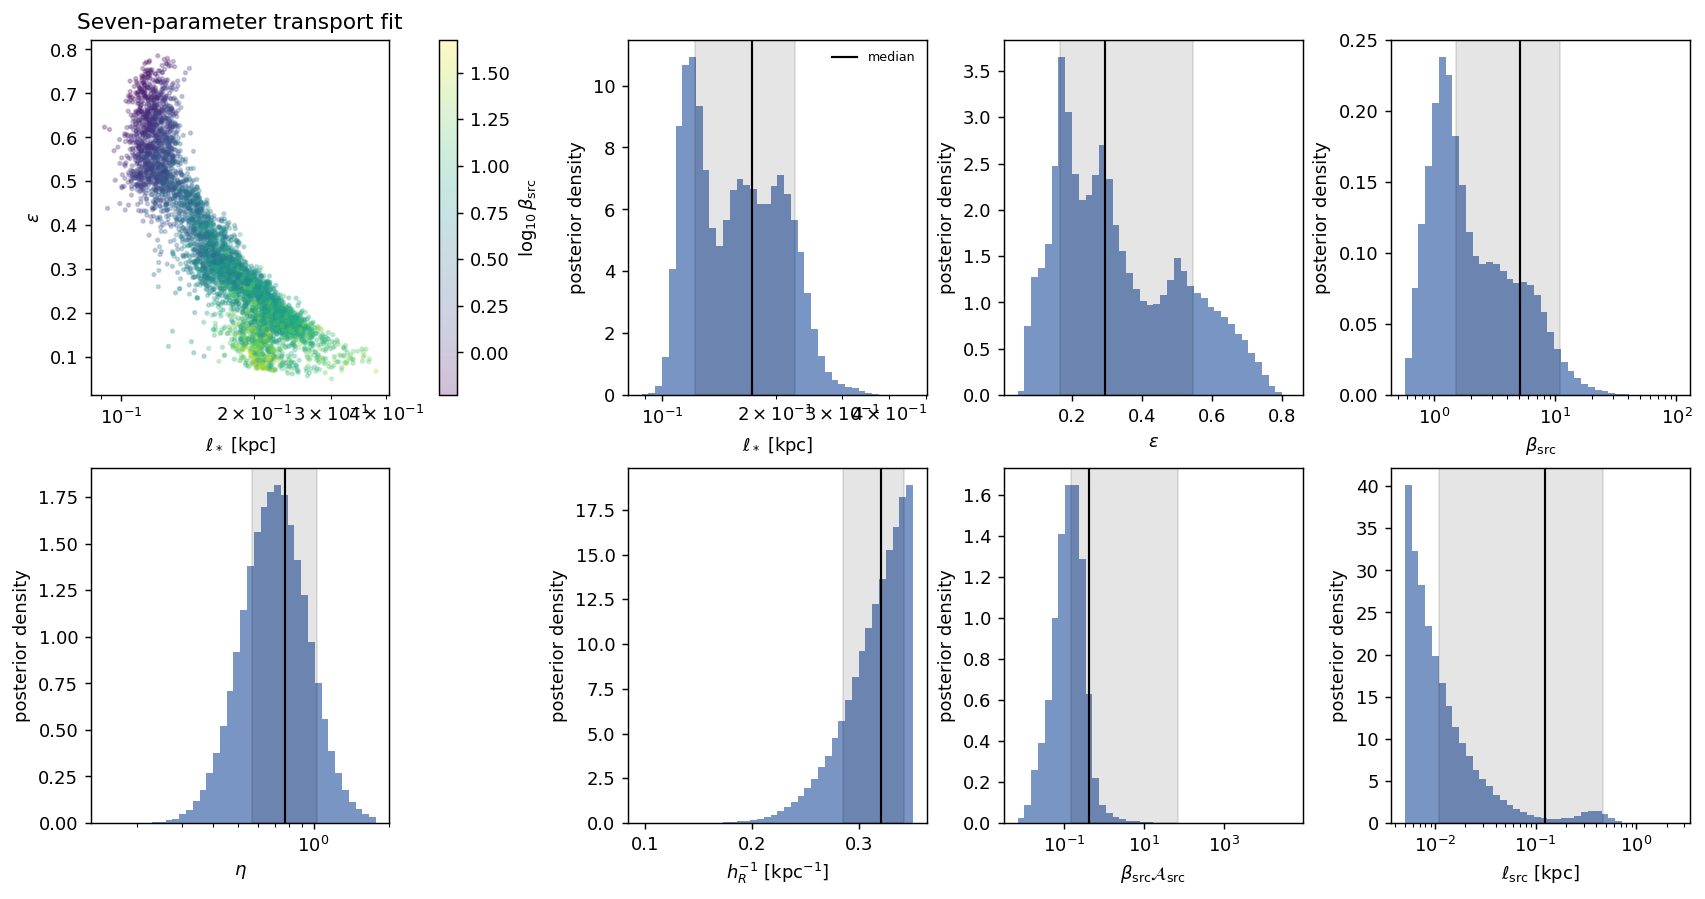

Maximum |posterior-median KTZ + isotropic C_NP - posterior-median KT18|: 0.047


In [14]:
fig, axes = plt.subplots(2, 4, figsize=(13.0, 6.8), constrained_layout=True)
diagnostic_draw = mcmc_rng.choice(
    len(posterior_log_samples), min(5000, len(posterior_log_samples)),
    replace=False,
)
scatter = axes[0, 0].scatter(
    posterior_samples["ell_star"][diagnostic_draw],
    posterior_samples["epsilon"][diagnostic_draw],
    c=np.log10(posterior_samples["beta"][diagnostic_draw]),
    s=4, alpha=0.25, cmap="viridis",
)
axes[0, 0].set_xscale("log")
axes[0, 0].set_xlabel(r"$\ell_*$ [kpc]")
axes[0, 0].set_ylabel(r"$\epsilon$")
axes[0, 0].set_title("Seven-parameter transport fit")
fig.colorbar(scatter, ax=axes[0, 0], label=r"$\log_{10}\beta_{\rm src}$")

diagnostic_specs = (
    (axes[0, 1], "ell_star", r"$\ell_*$ [kpc]", True),
    (axes[0, 2], "epsilon", r"$\epsilon$", False),
    (axes[0, 3], "beta", r"$\beta_{\rm src}$", True),
    (axes[1, 0], "eta", r"$\eta$", True),
    (axes[1, 1], "inv_h_R", r"$h_R^{-1}$ [kpc$^{-1}$]", False),
    (
        axes[1, 2], "beta_A_src",
        r"$\beta_{\rm src}{\cal A}_{\rm src}$", True,
    ),
    (
        axes[1, 3], "source_clustering_length",
        r"$\ell_{\rm src}$ [kpc]", True,
    ),
)
for axis, name, label, use_log_scale in diagnostic_specs:
    interval = credible_interval(posterior_samples[name])
    values = posterior_samples[name]
    histogram_bins = (
        np.geomspace(np.min(values[values > 0]), np.max(values), 41)
        if use_log_scale else 40
    )
    axis.hist(
        values, bins=histogram_bins, density=True,
        color="#4c72b0", alpha=0.75,
    )
    axis.axvline(interval[1], color="black", lw=1.2, label="median")
    axis.axvspan(interval[0], interval[2], color="black", alpha=0.10)
    axis.set_xlabel(label)
    axis.set_ylabel("posterior density")
    if use_log_scale:
        axis.set_xscale("log")
axes[0, 1].legend(frameon=False, fontsize=7.0)
fig.savefig(
    OUTPUT_DIR / "ngc4254_phangs_transport_posterior.png",
    bbox_inches="tight",
)
display_figure(fig)

print(
    "Maximum |posterior-median KTZ + isotropic C_NP - posterior-median KT18|: "
    f"{np.nanmax(np.abs(xi_full_ktz - xi_kt18)):.3f}"
)


## 6. Multi-element scope

This calculation tests only the oxygen correlation. A consistent multi-element application would require the same source-template moments and channel-dependent time histories; the former single-wavenumber forecast is not evaluated for this arbitrary two-dimensional map.


In [15]:
# Deliberately empty; see the methodological note above.


In [16]:
# Deliberately empty; see the methodological note above.


## 7. Interpretation and limits

- The metallicity statistic now follows the Li21 spaxel-selection logic:
  every diagnostic line has $S/N\geq2$, the [N II] BPT position lies below
  the Kewley boundary, and $\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  The
  PHANGS nebular mask does not select abundance pixels.
- PHANGS MAPS does not contain a continuum extension.  The EW map therefore
  uses the PSF-matched synthetic SDSS-$r$ flux density and is tied to the
  catalogue's fitted region-integrated H-alpha EWs.  Its per-galaxy calibration
  interval is recorded in the morphology summary and should be propagated as
  a selection sensitivity test.
- The primary KTZ fit has seven free parameters:
  $\ell_*$, $\epsilon$, $\beta_{\rm src}$, $\eta$, $h_R^{-1}$,
  $\beta_{\rm src}{\cal A}_{\rm src}$, and $\ell_{\rm src}$.  The direct
  H-alpha source grid supplies informative priors on $\eta$ and $h_R^{-1}$.
- The finite-window KTZ quadrature visits every valid unordered pixel pair exactly once; it does not sample pairs.  To keep the 60 pc Li21 grid tractable, exact counts and source-template moments are accumulated in 12 separation subbins per reported bin and 256 midpoint-radius bins.  The cached compression is checked bin by bin against the exact FFT pair counts.
- The likelihood uses all available positive-separation bins from the 60 pc
  grid out to 5 kpc.  The displayed $r=0$ observation and model are fixed to
  unity and do not enter the likelihood.
- Fluxes are matched to a 120 pc Gaussian PSF before ratios are formed.  The
  output is Nyquist-sampled at 60 pc, but independent information remains
  limited by the 120 pc beam.
- Missing or failed-selection cells remain `NaN`.  The FFT numerator is divided
  by an independently transformed binary mask, so internal zero filling never
  treats a missing pixel as zero metallicity fluctuation.
- A separate arithmetic mean is removed in every 0.2 kpc annulus, following
  Li21.  This guards against nonlinear radial calibration structure but also
  removes genuine axisymmetric radial modes.
  Its deterministic covariance projector is applied to both KTZ and KT18
  on the exact valid-pixel mask before the noise transfer.
- The observation transfer combines Li21 Gaussian-beam broadening with a
  200-realisation line-flux Monte Carlo.  Every realisation re-evaluates the
  line-S/N, BPT, and H-alpha-EW cuts; fixed-mask curves are retained as a
  paired control.  The 1.12 error inflation and Gaussian noise correlation
  remain approximations to covariance not supplied in the public MAPS product.
- Within complete KTZ, $C_{\rm NP}$ is the appendix prediction for a Gaussian
  pre-mixing source-pair excess filtered by injection and diffusion; it is not
  a freely added post-mixing Gaussian correlation.
- The executed robustness grid uses H-alpha-EW thresholds of 3, 6, and 12
  Angstrom and line-S/N thresholds of 2, 3, and 5.  Annular line-ratio
  shuffles additionally test correlation recovered solely by the released-map
  selection.  Alternative target beams and native-cube injection remain future
  robustness tests.
- The H-alpha template and abundance map share line noise, attenuation correction, and selection. Not using abundance residual values to build the template does not make the input data statistically independent.
- Template smoothing and geometry uncertainty are not included in the conditional posterior bands; the supplied sensitivity runs measure this additional systematic.


In [17]:
display(Markdown(
    "### Reproducible outputs\n\n"
    + "\n".join(
        f"- `{path.relative_to(ROOT)}`"
        for path in sorted(OUTPUT_DIR.glob("ngc4254_*"))
    )
))

### Reproducible outputs

- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_annular_detrending_transfer.npz`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_annulus_sensitivity.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_covariance_sensitivity.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_kt18_transport_chain.npz`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_kt18_transport_posterior.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_ktz_fit_summary.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_morphology_summary.json`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_muse_scal_7p_ktz_cnp_full_pair_emulator.npz`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_muse_scal_7p_ktz_full_pair_emulator.npz`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_muse_scal_exhaustive_pair_geometry.npz`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_muse_scal_metallicity_residual_pixel_map.npz`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_phangs_morphology.png`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_phangs_radial_selection.png`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_phangs_transport_posterior.png`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_residual_covariance_diagnostics.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_selection_response.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_selection_response_diagnostic.png`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_selection_summary.json`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_selection_threshold_grid.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_transport_chain.npz`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_transport_posterior.csv`
- `outputs/implications/NGC4254_halpha_map_fwhm1p5_systematic/ngc4254_xi_observed_and_models.csv`

## 8. Pre-specified H-alpha smoothing sensitivity

These are separate complete-KTZ fits at 0.5/1.0/1.5-kpc template FWHM, with the same abundance map, observing transfer, prior prescription, and seven likelihood coordinates. The tail mean is over 3.3--4.5 kpc. Smaller Q is a lower covariance-calibrated discrepancy, not model evidence. We retain 1.0 kpc as the declared central template rather than selecting the best curve. A failed convergence rule invalidates parameter conclusions from that run.

| FWHM [kpc] | calibrated Q | ell_star [kpc] | ell_src [kpc] | tail mean | max Rhat | status |
| --- | --- | --- | --- | --- | --- | --- |
| 0.5 | 0.691 | 0.124 | 0.033 | +0.0024 | 1.024 | converged |
| 1.0 | 0.718 | 0.153 | 0.030 | +0.0001 | 1.015 | converged |
| 1.5 | 0.781 | 0.173 | 0.122 | -0.0084 | 1.027 | converged |
